# Exploratory Data Analysis and Business Performance

## Objective

I analyze the cleaned Global Superstore data to identify meaningful patterns in sales, profitability, customers, products, discounts, returns, and geographic performance.

The analysis focuses on management-level business questions and uses only validated values from the processed datasets.

## Business Questions

1. How have revenue, profit, orders, customers, and average order value changed over time?
2. What seasonal and monthly sales patterns exist?
3. Which categories, sub-categories, and products generate the most revenue and profit?
4. Which high-sales products produce low or negative profit?
5. How does discounting affect profit margin and loss frequency?
6. Which markets, countries, and regions perform best and worst?
7. Who are the highest-value and largest-loss customers?
8. How do repeat customers differ from one-time customers?
9. How much revenue comes from new and returning customer orders?
10. How can customers be segmented using RFM analysis?
11. Can a transparent 12-month customer-value proxy be estimated?
12. Which products appear most frequently in returned orders?
13. Which findings require immediate management attention?

## 1. Environment and Project Paths

I configure the analysis environment and locate the processed datasets using relative project paths.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Locate the project folder from either the project root or notebooks folder

current_folder = Path.cwd()

if current_folder.name.lower() == "notebooks":
    project_folder = current_folder.parent
else:
    project_folder = current_folder

processed_data_folder = project_folder / "data" / "processed"

if not processed_data_folder.exists():
    raise FileNotFoundError(
        f"Processed data folder was not found: {processed_data_folder}"
    )


# Configure consistent notebook and chart presentation

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titleweight"] = "bold"


print("Current folder:", current_folder.name)
print("Project folder:", project_folder.name)
print("Processed data folder:", processed_data_folder)
print("Processed folder exists:", processed_data_folder.exists())

Current folder: notebooks
Project folder: ecommerce_sales_customer_profitability_analytics
Processed data folder: C:\Users\niles\Nilesh\ecommerce_sales_customer_profitability_analytics\data\processed
Processed folder exists: True


## 2. Load and Validate Processed Data

I load the main analysis-ready Orders dataset created during the cleaning phase and confirm its dimensions before calculating business metrics.

In [2]:
orders = pd.read_csv(
    processed_data_folder / "orders_cleaned.csv",
    encoding="utf-8-sig",
    dtype={"postal_code": "string"},
    parse_dates=["order_date", "ship_date"],
    low_memory=False
)

print(
    f"Orders dataset: "
    f"{orders.shape[0]:,} rows x "
    f"{orders.shape[1]} columns"
)

Orders dataset: 51,290 rows x 38 columns


### 2.1 Analysis Scope and Data Grain

The primary dataset is stored at the sales-line level. I use the validated `order_key` for order-level metrics and `customer_key` for customer-level metrics.

**Customer identity note:** The cleaned dataset uses a name-based surrogate `customer_key` because the raw Customer IDs contain geography-specific variants. Customer metrics therefore represent named customer entities within this dataset, not independently verified real-world identities.

In [3]:
required_analysis_columns = {
    "row_id",
    "order_key",
    "order_date",
    "customer_key",
    "product_id",
    "category",
    "sub_category",
    "sales",
    "profit",
    "quantity",
    "discount",
    "market",
    "country",
    "region",
    "is_returned"
}

missing_analysis_columns = sorted(
    required_analysis_columns.difference(orders.columns)
)

if missing_analysis_columns:
    raise KeyError(
        f"Required analysis columns are missing: {missing_analysis_columns}"
    )

if not orders["row_id"].is_unique:
    raise ValueError("Row ID is not unique in the processed Orders dataset.")


analysis_scope = pd.DataFrame({
    "Metric": [
        "Sales Lines",
        "Analytical Orders",
        "Unique Customers",
        "Unique Products",
        "Returned Analytical Orders",
        "Order Date Range"
    ],
    "Value": [
        f"{len(orders):,}",
        f"{orders['order_key'].nunique():,}",
        f"{orders['customer_key'].nunique():,}",
        f"{orders['product_id'].nunique():,}",
        f"{orders.loc[orders['is_returned'], 'order_key'].nunique():,}",
        (
            f"{orders['order_date'].min():%Y-%m-%d} "
            f"to {orders['order_date'].max():%Y-%m-%d}"
        )
    ]
})

display(analysis_scope)

,Metric,Value
0,Sales Lines,"51,290"
1,Analytical Orders,"25,739"
2,Unique Customers,796
3,Unique Products,"3,788"
4,Returned Analytical Orders,"1,079"
5,Order Date Range,2012-01-01 to 2015-12-31


## 3. Executive KPI Overview

I establish the company's overall performance baseline using clearly defined revenue, profitability, order, customer, and return metrics.

In [4]:
total_revenue = orders["sales"].sum()
total_profit = orders["profit"].sum()

total_orders = orders["order_key"].nunique()
unique_customers = orders["customer_key"].nunique()
total_quantity = orders["quantity"].sum()

returned_orders = orders.loc[
    orders["is_returned"], "order_key"
].nunique()


profit_margin = total_profit / total_revenue
average_order_value = total_revenue / total_orders
return_rate = returned_orders / total_orders
revenue_per_customer = total_revenue / unique_customers


kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Profit",
        "Profit Margin",
        "Total Orders",
        "Unique Customers",
        "Total Quantity",
        "Average Order Value",
        "Return Rate",
        "Revenue per Customer"
    ],
    "Value": [
        f"${total_revenue:,.2f}",
        f"${total_profit:,.2f}",
        f"{profit_margin:.2%}",
        f"{total_orders:,}",
        f"{unique_customers:,}",
        f"{total_quantity:,}",
        f"${average_order_value:,.2f}",
        f"{return_rate:.2%}",
        f"${revenue_per_customer:,.2f}"
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Revenue,"$12,642,507.25"
1,Total Profit,"$1,467,456.67"
2,Profit Margin,11.61%
3,Total Orders,"25,739"
4,Unique Customers,796
5,Total Quantity,"178,312"
6,Average Order Value,$491.18
7,Return Rate,4.19%
8,Revenue per Customer,"$15,882.55"


## 4. Revenue and Profit Trends Over Time

### 4.1 Annual Performance

I compare annual revenue, profit, margin, orders, customers, and average order value to evaluate the company's long-term performance.

In [5]:
yearly_performance = (
    orders
    .groupby("order_year", as_index=False)
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_key", "nunique"),
        customers=("customer_key", "nunique"),
        quantity=("quantity", "sum")
    )
    .sort_values("order_year")
)

yearly_performance["profit_margin"] = (
    yearly_performance["profit"]
    / yearly_performance["revenue"]
)

yearly_performance["average_order_value"] = (
    yearly_performance["revenue"]
    / yearly_performance["orders"]
)

yearly_performance["revenue_yoy_growth"] = (
    yearly_performance["revenue"].pct_change()
)


yearly_performance_display = yearly_performance.copy()

yearly_performance_display["revenue"] = (
    yearly_performance_display["revenue"]
    .map("${:,.2f}".format)
)

yearly_performance_display["profit"] = (
    yearly_performance_display["profit"]
    .map("${:,.2f}".format)
)

yearly_performance_display["profit_margin"] = (
    yearly_performance_display["profit_margin"]
    .map("{:.2%}".format)
)

yearly_performance_display["average_order_value"] = (
    yearly_performance_display["average_order_value"]
    .map("${:,.2f}".format)
)

yearly_performance_display["revenue_yoy_growth"] = (
    yearly_performance_display["revenue_yoy_growth"]
    .map(lambda value: "N/A" if pd.isna(value) else f"{value:.2%}")
)

yearly_performance_display = yearly_performance_display.rename(
    columns={
        "order_year": "Year",
        "revenue": "Revenue",
        "profit": "Profit",
        "orders": "Orders",
        "customers": "Customers",
        "quantity": "Quantity",
        "profit_margin": "Profit Margin",
        "average_order_value": "Average Order Value",
        "revenue_yoy_growth": "Revenue YoY Growth"
    }
)

display(yearly_performance_display)

,Year,Revenue,Profit,Orders,Customers,Quantity,Profit Margin,Average Order Value,Revenue YoY Growth
0,2012,"$2,259,451.64","$248,940.35",4516,795,31443,11.02%,$500.32,N/A
1,2013,"$2,677,439.91","$307,415.33",5476,795,38111,11.48%,$488.94,18.50%
2,2014,"$3,405,748.03","$406,934.89",6887,796,48136,11.95%,$494.52,27.20%
3,2015,"$4,299,867.67","$504,166.10",8860,794,60622,11.73%,$485.31,26.25%


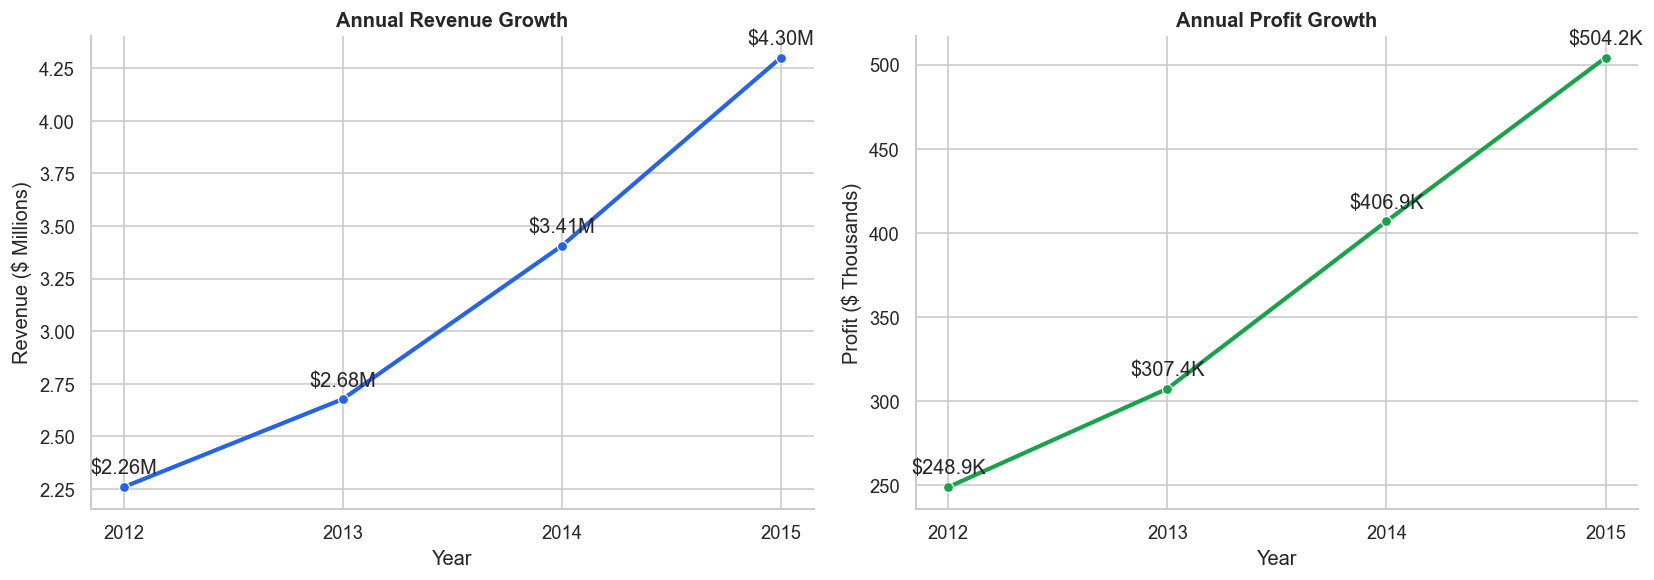

In [6]:
annual_chart_data = yearly_performance.copy()

annual_chart_data["revenue_millions"] = (
    annual_chart_data["revenue"] / 1_000_000
)

annual_chart_data["profit_thousands"] = (
    annual_chart_data["profit"] / 1_000
)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.lineplot(
    data=annual_chart_data,
    x="order_year",
    y="revenue_millions",
    marker="o",
    linewidth=2.5,
    color="#2563EB",
    ax=axes[0]
)

axes[0].set_title("Annual Revenue Growth")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Revenue ($ Millions)")
axes[0].set_xticks(annual_chart_data["order_year"])

for row in annual_chart_data.itertuples():
    axes[0].annotate(
        f"${row.revenue_millions:.2f}M",
        (row.order_year, row.revenue_millions),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )


sns.lineplot(
    data=annual_chart_data,
    x="order_year",
    y="profit_thousands",
    marker="o",
    linewidth=2.5,
    color="#16A34A",
    ax=axes[1]
)

axes[1].set_title("Annual Profit Growth")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Profit ($ Thousands)")
axes[1].set_xticks(annual_chart_data["order_year"])

for row in annual_chart_data.itertuples():
    axes[1].annotate(
        f"${row.profit_thousands:.1f}K",
        (row.order_year, row.profit_thousands),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )


sns.despine()
plt.tight_layout()
plt.show()

### Annual Performance Findings

- Revenue increased every year, reaching $4.30 million in 2015, while profit reached $504.17 thousand.
- Revenue growth accelerated from **18.50% in 2013** to **27.20% in 2014** and remained strong at **26.25% in 2015**.
- Profit margin improved from **11.02% in 2012** to a peak of **11.95% in 2014**, before declining slightly to **11.73% in 2015**.
- Annual orders increased from **4,516 to 8,860**, while average order value decreased from **$500.32 to $485.31**.
- The annual customer count remained almost unchanged at approximately **794–796 customers**.

**Business interpretation:** Revenue growth was driven primarily by higher order activity from a largely stable customer base, rather than customer-base expansion or larger order values. Management should investigate customer acquisition opportunities and the slight margin decline observed in 2015.

### 4.2 Monthly Performance Trend

I calculate monthly revenue, profit, orders, average order value, profit margin, and month-over-month revenue growth to identify short-term performance changes.

In [7]:
monthly_performance = (
    orders
    .groupby(
        pd.Grouper(
            key="order_date",
            freq="MS"
        ),
        as_index=False
    )
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_key", "nunique"),
        customers=("customer_key", "nunique")
    )
    .rename(columns={"order_date": "month"})
    .sort_values("month")
)

monthly_performance["profit_margin"] = (
    monthly_performance["profit"]
    / monthly_performance["revenue"]
)

monthly_performance["average_order_value"] = (
    monthly_performance["revenue"]
    / monthly_performance["orders"]
)

monthly_performance["revenue_mom_growth"] = (
    monthly_performance["revenue"].pct_change()
)


monthly_display = monthly_performance.tail(12).copy()

monthly_display["month"] = (
    monthly_display["month"].dt.strftime("%Y-%m")
)

monthly_display["revenue"] = (
    monthly_display["revenue"].map("${:,.2f}".format)
)

monthly_display["profit"] = (
    monthly_display["profit"].map("${:,.2f}".format)
)

monthly_display["profit_margin"] = (
    monthly_display["profit_margin"].map("{:.2%}".format)
)

monthly_display["average_order_value"] = (
    monthly_display["average_order_value"].map("${:,.2f}".format)
)

monthly_display["revenue_mom_growth"] = (
    monthly_display["revenue_mom_growth"].map("{:+.2%}".format)
)

monthly_display = monthly_display.rename(
    columns={
        "month": "Month",
        "revenue": "Revenue",
        "profit": "Profit",
        "orders": "Orders",
        "customers": "Customers",
        "profit_margin": "Profit Margin",
        "average_order_value": "Average Order Value",
        "revenue_mom_growth": "Revenue MoM Growth"
    }
)

print("Monthly periods available:", len(monthly_performance))
print(
    "Monthly range:",
    monthly_performance["month"].min().strftime("%Y-%m"),
    "to",
    monthly_performance["month"].max().strftime("%Y-%m")
)

display(monthly_display)

Monthly periods available: 48
Monthly range: 2012-01 to 2015-12


,Month,Revenue,Profit,Orders,Customers,Profit Margin,Average Order Value,Revenue MoM Growth
36,2015-01,"$241,268.65","$28,001.38",450,344,11.61%,$536.15,-40.49%
37,2015-02,"$184,837.46","$19,751.71",385,317,10.69%,$480.10,-23.39%
38,2015-03,"$263,100.83","$37,357.16",531,386,14.20%,$495.48,+42.34%
39,2015-04,"$242,772.01","$23,782.32",524,383,9.80%,$463.31,-7.73%
40,2015-05,"$288,401.13","$33,953.63",669,443,11.77%,$431.09,+18.80%
41,2015-06,"$401,814.19","$43,778.55",902,542,10.90%,$445.47,+39.32%
42,2015-07,"$258,705.80","$28,035.81",541,375,10.84%,$478.20,-35.62%
43,2015-08,"$456,620.18","$53,542.99",848,513,11.73%,$538.47,+76.50%
44,2015-09,"$481,157.41","$67,979.54",1019,574,14.13%,$472.19,+5.37%
45,2015-10,"$422,766.85","$58,209.97",810,507,13.77%,$521.93,-12.14%


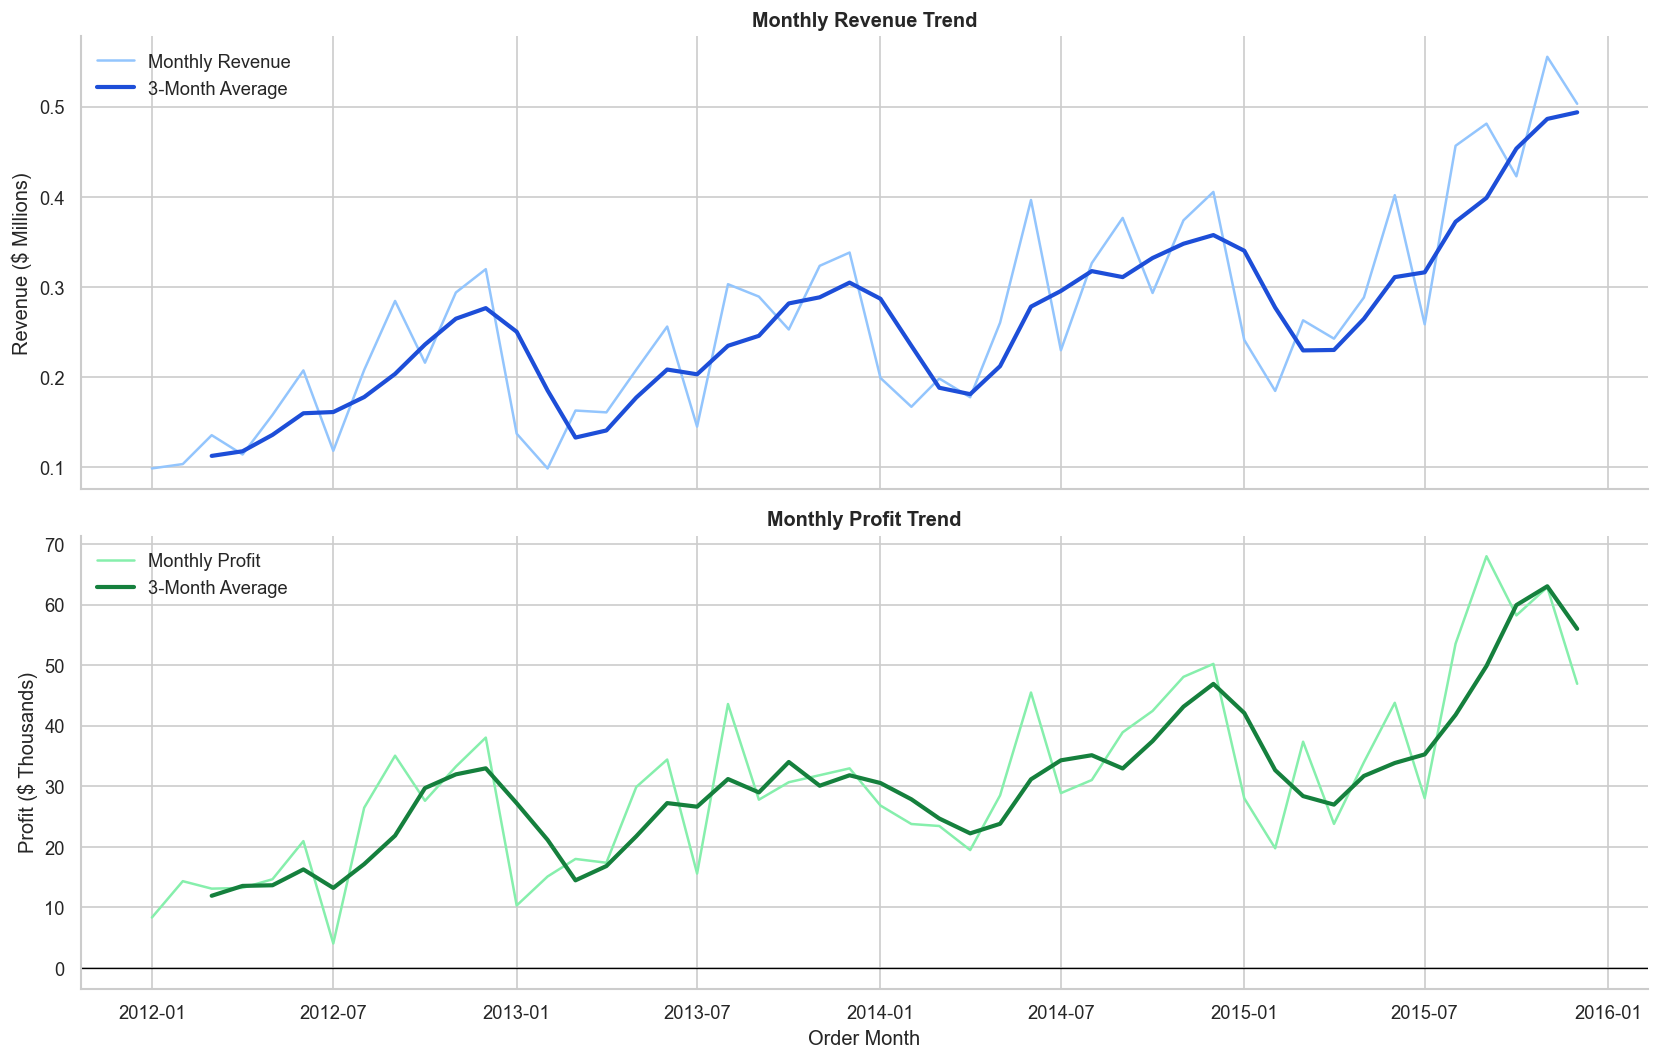

In [8]:
monthly_performance["revenue_3m_average"] = (
    monthly_performance["revenue"]
    .rolling(window=3)
    .mean()
)

monthly_performance["profit_3m_average"] = (
    monthly_performance["profit"]
    .rolling(window=3)
    .mean()
)


monthly_chart_data = monthly_performance.copy()

monthly_chart_data["revenue_millions"] = (
    monthly_chart_data["revenue"] / 1_000_000
)

monthly_chart_data["revenue_3m_millions"] = (
    monthly_chart_data["revenue_3m_average"] / 1_000_000
)

monthly_chart_data["profit_thousands"] = (
    monthly_chart_data["profit"] / 1_000
)

monthly_chart_data["profit_3m_thousands"] = (
    monthly_chart_data["profit_3m_average"] / 1_000
)


fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9),
    sharex=True
)


sns.lineplot(
    data=monthly_chart_data,
    x="month",
    y="revenue_millions",
    color="#93C5FD",
    linewidth=1.5,
    label="Monthly Revenue",
    ax=axes[0]
)

sns.lineplot(
    data=monthly_chart_data,
    x="month",
    y="revenue_3m_millions",
    color="#1D4ED8",
    linewidth=2.5,
    label="3-Month Average",
    ax=axes[0]
)

axes[0].set_title("Monthly Revenue Trend")
axes[0].set_xlabel("")
axes[0].set_ylabel("Revenue ($ Millions)")
axes[0].legend(frameon=False)


sns.lineplot(
    data=monthly_chart_data,
    x="month",
    y="profit_thousands",
    color="#86EFAC",
    linewidth=1.5,
    label="Monthly Profit",
    ax=axes[1]
)

sns.lineplot(
    data=monthly_chart_data,
    x="month",
    y="profit_3m_thousands",
    color="#15803D",
    linewidth=2.5,
    label="3-Month Average",
    ax=axes[1]
)

axes[1].axhline(
    0,
    color="black",
    linewidth=0.8
)

axes[1].set_title("Monthly Profit Trend")
axes[1].set_xlabel("Order Month")
axes[1].set_ylabel("Profit ($ Thousands)")
axes[1].legend(frameon=False)


sns.despine()
plt.tight_layout()
plt.show()

### 4.3 Monthly Seasonality

I compare the same calendar months across all four years to identify recurring high- and low-performance periods.

In [9]:
monthly_performance["month_number"] = (
    monthly_performance["month"].dt.month
)


seasonality = (
    monthly_performance
    .groupby("month_number", as_index=False)
    .agg(
        average_monthly_revenue=("revenue", "mean"),
        average_monthly_profit=("profit", "mean"),
        average_monthly_orders=("orders", "mean"),
        total_revenue=("revenue", "sum"),
        total_profit=("profit", "sum")
    )
    .sort_values("month_number")
)

seasonality["month_name"] = (
    seasonality["month_number"]
    .map(
        lambda month_number:
        pd.Timestamp(2000, month_number, 1).month_name()
    )
)

seasonality["profit_margin"] = (
    seasonality["total_profit"]
    / seasonality["total_revenue"]
)


seasonality_display = seasonality[
    [
        "month_name",
        "average_monthly_revenue",
        "average_monthly_profit",
        "average_monthly_orders",
        "profit_margin"
    ]
].copy()

seasonality_display["average_monthly_revenue"] = (
    seasonality_display["average_monthly_revenue"]
    .map("${:,.2f}".format)
)

seasonality_display["average_monthly_profit"] = (
    seasonality_display["average_monthly_profit"]
    .map("${:,.2f}".format)
)

seasonality_display["average_monthly_orders"] = (
    seasonality_display["average_monthly_orders"]
    .map("{:,.1f}".format)
)

seasonality_display["profit_margin"] = (
    seasonality_display["profit_margin"]
    .map("{:.2%}".format)
)

seasonality_display = seasonality_display.rename(
    columns={
        "month_name": "Month",
        "average_monthly_revenue": "Average Monthly Revenue",
        "average_monthly_profit": "Average Monthly Profit",
        "average_monthly_orders": "Average Monthly Orders",
        "profit_margin": "Profit Margin"
    }
)

display(seasonality_display)

,Month,Average Monthly Revenue,Average Monthly Profit,Average Monthly Orders,Profit Margin
0,January,"$169,197.33","$18,360.11",319.5,10.85%
1,February,"$138,662.55","$18,233.04",279.2,13.15%
2,March,"$190,129.59","$22,968.36",386.5,12.08%
3,April,"$173,994.71","$18,455.64",374.8,10.61%
4,May,"$228,873.31","$26,742.52",480.8,11.68%
5,June,"$315,520.32","$36,151.09",664.0,11.46%
6,July,"$188,076.61","$19,131.38",393.5,10.17%
7,August,"$323,578.89","$38,648.37",628.0,11.94%
8,September,"$357,938.50","$42,426.49",753.5,11.85%
9,October,"$296,307.03","$39,726.00",579.0,13.41%


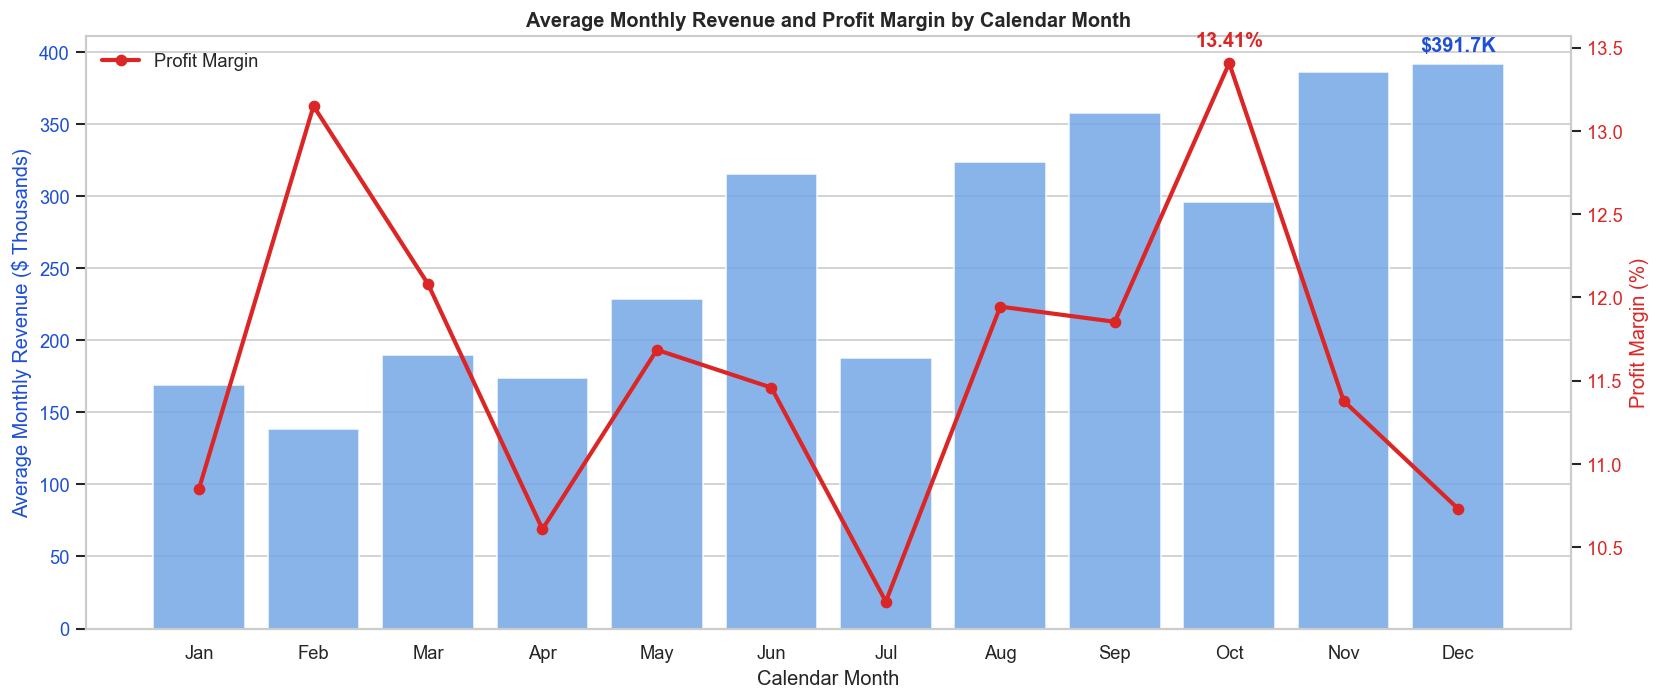

In [10]:
seasonality_chart_data = seasonality.copy()

seasonality_chart_data["month_label"] = (
    seasonality_chart_data["month_name"].str[:3]
)

seasonality_chart_data["revenue_thousands"] = (
    seasonality_chart_data["average_monthly_revenue"] / 1_000
)

seasonality_chart_data["profit_margin_percent"] = (
    seasonality_chart_data["profit_margin"] * 100
)


fig, revenue_axis = plt.subplots(figsize=(14, 6))

sns.barplot(
    data=seasonality_chart_data,
    x="month_label",
    y="revenue_thousands",
    color="#60A5FA",
    alpha=0.85,
    ax=revenue_axis
)

revenue_axis.set_title(
    "Average Monthly Revenue and Profit Margin by Calendar Month"
)
revenue_axis.set_xlabel("Calendar Month")
revenue_axis.set_ylabel(
    "Average Monthly Revenue ($ Thousands)",
    color="#1D4ED8"
)
revenue_axis.tick_params(
    axis="y",
    labelcolor="#1D4ED8"
)


margin_axis = revenue_axis.twinx()

margin_axis.plot(
    seasonality_chart_data["month_label"],
    seasonality_chart_data["profit_margin_percent"],
    color="#DC2626",
    marker="o",
    linewidth=2.5,
    label="Profit Margin"
)

margin_axis.set_ylabel(
    "Profit Margin (%)",
    color="#DC2626"
)
margin_axis.tick_params(
    axis="y",
    labelcolor="#DC2626"
)
margin_axis.grid(False)


peak_revenue = seasonality_chart_data.loc[
    seasonality_chart_data["average_monthly_revenue"].idxmax()
]

peak_margin = seasonality_chart_data.loc[
    seasonality_chart_data["profit_margin"].idxmax()
]


revenue_axis.annotate(
    f"${peak_revenue['revenue_thousands']:.1f}K",
    (
        peak_revenue["month_number"] - 1,
        peak_revenue["revenue_thousands"]
    ),
    textcoords="offset points",
    xytext=(0, 8),
    ha="center",
    color="#1D4ED8",
    fontweight="bold"
)

margin_axis.annotate(
    f"{peak_margin['profit_margin_percent']:.2f}%",
    (
        peak_margin["month_number"] - 1,
        peak_margin["profit_margin_percent"]
    ),
    textcoords="offset points",
    xytext=(0, 10),
    ha="center",
    color="#DC2626",
    fontweight="bold"
)


margin_axis.legend(
    loc="upper left",
    frameon=False
)

sns.despine(
    ax=revenue_axis,
    right=False
)

plt.tight_layout()
plt.show()

### Seasonality Findings

- Revenue follows a clear seasonal pattern, with the strongest average performance in **November and December**.
- December generated the highest average monthly revenue of **$391.67 thousand** and the highest average order volume of approximately **790 orders**.
- November generated the highest average monthly profit of **$44.00 thousand**.
- October achieved the highest profit margin at **13.41%**, despite generating less revenue than November and December.
- February recorded the lowest average revenue at **$138.66 thousand**, while July recorded the lowest profit margin at **10.17%**.
- December's high revenue but lower **10.73% margin** indicates that peak-season sales volume does not automatically produce the strongest profitability.

**Business implication:** Management should prepare inventory and operational capacity for the August-to-December demand increase, while reviewing discounting and product mix during December to protect margin.

## 5. Product and Profitability Analysis

### 5.1 Category Performance

I compare category-level revenue, profit, margin, quantity, product coverage, and contribution to overall company performance.

In [11]:
category_performance = (
    orders
    .groupby("category", as_index=False)
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        quantity=("quantity", "sum"),
        orders_containing_category=("order_key", "nunique"),
        unique_products=("product_id", "nunique")
    )
)

category_performance["profit_margin"] = (
    category_performance["profit"]
    / category_performance["revenue"]
)

category_performance["revenue_share"] = (
    category_performance["revenue"]
    / total_revenue
)

category_performance["profit_share"] = (
    category_performance["profit"]
    / total_profit
)

category_performance = category_performance.sort_values(
    "revenue",
    ascending=False
).reset_index(drop=True)


category_display = category_performance.copy()

category_display["revenue"] = (
    category_display["revenue"].map("${:,.2f}".format)
)

category_display["profit"] = (
    category_display["profit"].map("${:,.2f}".format)
)

category_display["profit_margin"] = (
    category_display["profit_margin"].map("{:.2%}".format)
)

category_display["revenue_share"] = (
    category_display["revenue_share"].map("{:.2%}".format)
)

category_display["profit_share"] = (
    category_display["profit_share"].map("{:.2%}".format)
)

category_display = category_display.rename(
    columns={
        "category": "Category",
        "revenue": "Revenue",
        "profit": "Profit",
        "quantity": "Quantity",
        "orders_containing_category": "Orders Containing Category",
        "unique_products": "Unique Products",
        "profit_margin": "Profit Margin",
        "revenue_share": "Revenue Share",
        "profit_share": "Profit Share"
    }
)

display(category_display)

,Category,Revenue,Profit,Quantity,Orders Containing Category,Unique Products,Profit Margin,Revenue Share,Profit Share
0,Technology,"$4,744,558.76","$663,779.21",35176,8429,876,13.99%,37.53%,45.23%
1,Furniture,"$4,110,453.03","$285,082.62",34892,8224,841,6.94%,32.51%,19.43%
2,Office Supplies,"$3,787,495.46","$518,594.84",108244,19468,2071,13.69%,29.96%,35.34%


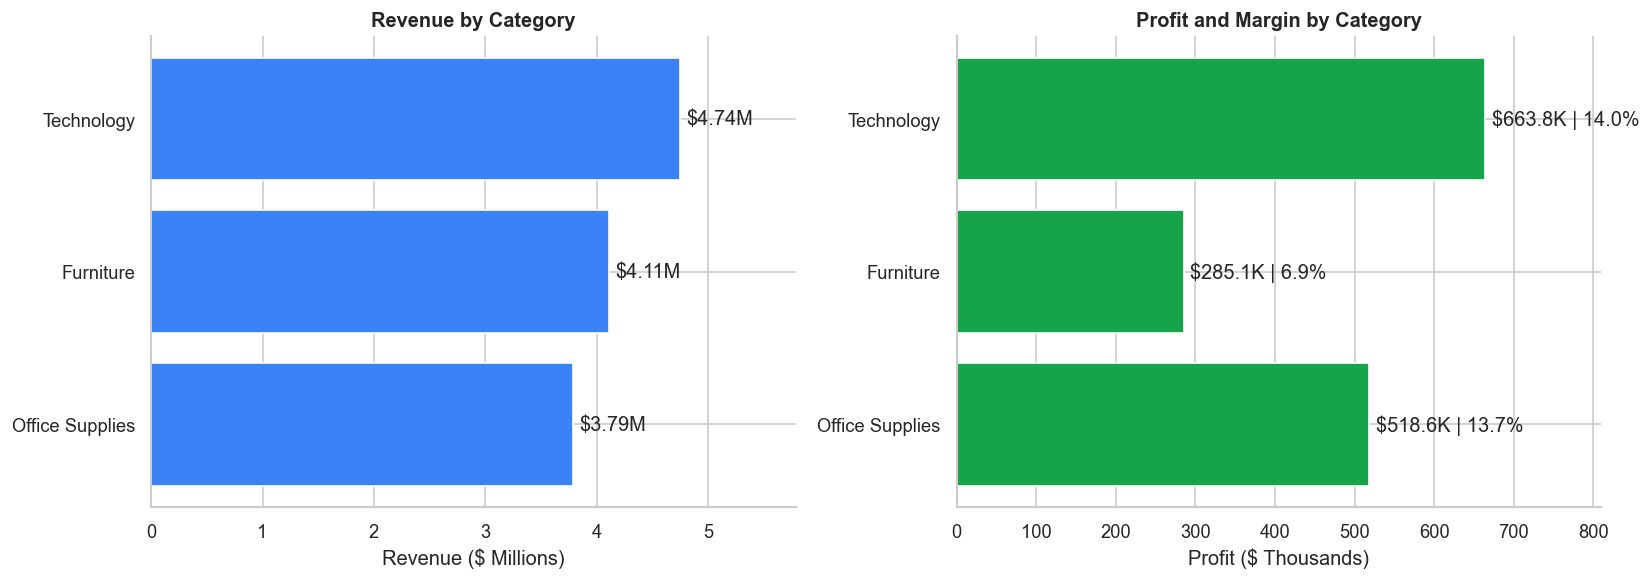

In [12]:
category_chart_data = (
    category_performance
    .sort_values("revenue", ascending=True)
    .copy()
)

category_chart_data["revenue_millions"] = (
    category_chart_data["revenue"] / 1_000_000
)

category_chart_data["profit_thousands"] = (
    category_chart_data["profit"] / 1_000
)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))


revenue_bars = axes[0].barh(
    category_chart_data["category"],
    category_chart_data["revenue_millions"],
    color="#3B82F6"
)

axes[0].set_title("Revenue by Category")
axes[0].set_xlabel("Revenue ($ Millions)")
axes[0].set_ylabel("")

axes[0].bar_label(
    revenue_bars,
    labels=[
        f"${value:.2f}M"
        for value in category_chart_data["revenue_millions"]
    ],
    padding=4
)


profit_bars = axes[1].barh(
    category_chart_data["category"],
    category_chart_data["profit_thousands"],
    color="#16A34A"
)

axes[1].set_title("Profit and Margin by Category")
axes[1].set_xlabel("Profit ($ Thousands)")
axes[1].set_ylabel("")

axes[1].bar_label(
    profit_bars,
    labels=[
        f"${profit:.1f}K | {margin:.1%}"
        for profit, margin in zip(
            category_chart_data["profit_thousands"],
            category_chart_data["profit_margin"]
        )
    ],
    padding=4
)


for axis in axes:
    axis.margins(x=0.22)

sns.despine()
plt.tight_layout()
plt.show()

### Category Findings

- **Technology** was the strongest category, contributing **37.53% of revenue** and **45.23% of total profit**, with a **13.99% margin**.
- **Office Supplies** generated **29.96% of revenue** but contributed a higher **35.34% of profit**, with a healthy **13.69% margin**.
- **Furniture** generated **32.51% of revenue** but only **19.43% of profit**.
- Furniture's **6.94% profit margin** was approximately half the margin achieved by the other two categories.

**Business implication:** Furniture requires deeper sub-category and product-level investigation to identify the sources of margin leakage before management changes pricing or discount policies.

### 5.2 Sub-Category Performance

I evaluate each sub-category using revenue, profit, margin, order participation, quantity, and average line-level discount.

In [13]:
sub_category_performance = (
    orders
    .groupby(
        ["category", "sub_category"],
        as_index=False
    )
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        quantity=("quantity", "sum"),
        orders_containing_sub_category=("order_key", "nunique"),
        average_line_discount=("discount", "mean")
    )
)

sub_category_performance["profit_margin"] = (
    sub_category_performance["profit"]
    / sub_category_performance["revenue"]
)

sub_category_performance["profit_status"] = np.where(
    sub_category_performance["profit"] < 0,
    "Loss-Making",
    "Profitable"
)

sub_category_performance = (
    sub_category_performance
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)


sub_category_display = sub_category_performance.copy()

sub_category_display["revenue"] = (
    sub_category_display["revenue"].map("${:,.2f}".format)
)

sub_category_display["profit"] = (
    sub_category_display["profit"].map("${:,.2f}".format)
)

sub_category_display["profit_margin"] = (
    sub_category_display["profit_margin"].map("{:.2%}".format)
)

sub_category_display["average_line_discount"] = (
    sub_category_display["average_line_discount"]
    .map("{:.2%}".format)
)

sub_category_display = sub_category_display.rename(
    columns={
        "category": "Category",
        "sub_category": "Sub-Category",
        "revenue": "Revenue",
        "profit": "Profit",
        "quantity": "Quantity",
        "orders_containing_sub_category": (
            "Orders Containing Sub-Category"
        ),
        "average_line_discount": "Average Line Discount",
        "profit_margin": "Profit Margin",
        "profit_status": "Profit Status"
    }
)

display(sub_category_display)

,Category,Sub-Category,Revenue,Profit,Quantity,Orders Containing Sub-Category,Average Line Discount,Profit Margin,Profit Status
0,Technology,Phones,"$1,706,824.65","$216,717.44",11870,3141,14.58%,12.70%,Profitable
1,Technology,Copiers,"$1,509,436.51","$258,567.63",7454,2124,11.71%,17.13%,Profitable
2,Furniture,Chairs,"$1,501,682.16","$140,396.24",12336,3198,16.31%,9.35%,Profitable
3,Furniture,Bookcases,"$1,466,572.55","$161,924.37",8310,2285,15.38%,11.04%,Profitable
4,Office Supplies,Storage,"$1,126,813.78","$108,416.94",16884,4565,13.85%,9.62%,Profitable
5,Office Supplies,Appliances,"$1,010,535.76","$141,562.63",6026,1676,14.21%,14.01%,Profitable
6,Technology,Machines,"$779,060.32","$58,867.70",4906,1426,16.96%,7.56%,Profitable
7,Furniture,Tables,"$757,042.17","$-64,083.55",3083,835,29.07%,-8.46%,Loss-Making
8,Technology,Accessories,"$749,237.28","$129,626.44",10946,2893,12.05%,17.30%,Profitable
9,Office Supplies,Binders,"$461,870.09","$72,432.92",21403,5432,17.93%,15.68%,Profitable


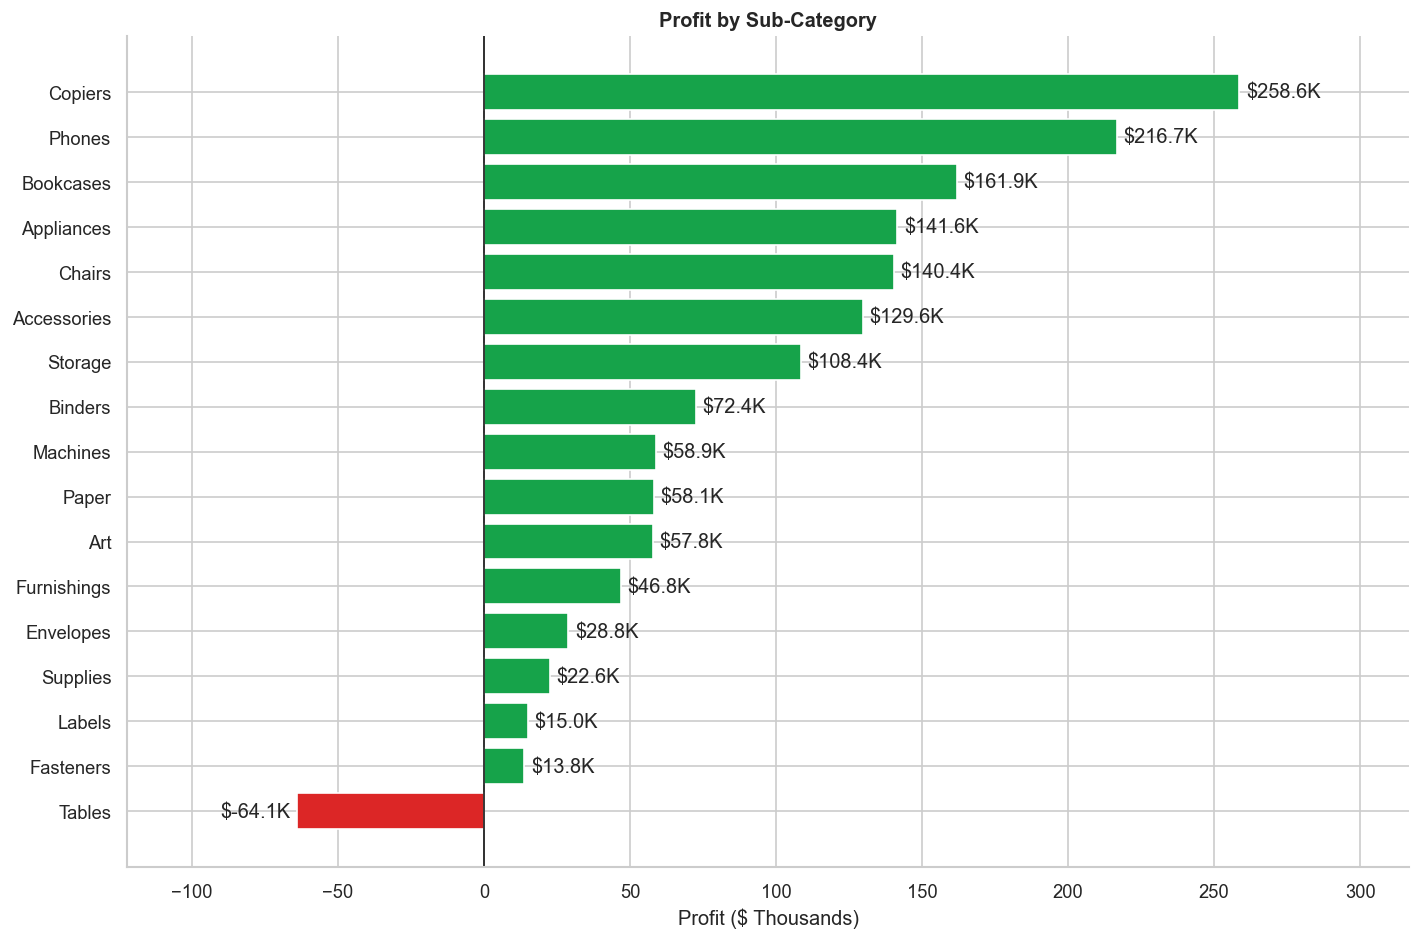

In [14]:
sub_category_profit_chart = (
    sub_category_performance
    .sort_values("profit", ascending=True)
    .copy()
)

bar_colors = np.where(
    sub_category_profit_chart["profit"] < 0,
    "#DC2626",
    "#16A34A"
)


fig, axis = plt.subplots(figsize=(12, 8))

profit_bars = axis.barh(
    sub_category_profit_chart["sub_category"],
    sub_category_profit_chart["profit"] / 1_000,
    color=bar_colors
)

axis.axvline(
    0,
    color="black",
    linewidth=0.9
)

axis.set_title("Profit by Sub-Category")
axis.set_xlabel("Profit ($ Thousands)")
axis.set_ylabel("")

axis.bar_label(
    profit_bars,
    labels=[
        f"${value / 1_000:,.1f}K"
        for value in sub_category_profit_chart["profit"]
    ],
    padding=4
)

axis.margins(x=0.18)

sns.despine()
plt.tight_layout()
plt.show()

### 5.3 Furniture Margin Diagnostic

I compare Furniture performance with and without the Tables sub-category to quantify its impact on category profitability. This is a diagnostic comparison and does not assume that Tables should be discontinued.

In [15]:
furniture_all = orders.loc[
    orders["category"].eq("Furniture")
].copy()

furniture_excluding_tables = furniture_all.loc[
    furniture_all["sub_category"].ne("Tables")
].copy()


furniture_diagnostic = pd.DataFrame([
    {
        "Scenario": "All Furniture",
        "Revenue": furniture_all["sales"].sum(),
        "Profit": furniture_all["profit"].sum()
    },
    {
        "Scenario": "Furniture excluding Tables",
        "Revenue": furniture_excluding_tables["sales"].sum(),
        "Profit": furniture_excluding_tables["profit"].sum()
    }
])

furniture_diagnostic["Profit Margin"] = (
    furniture_diagnostic["Profit"]
    / furniture_diagnostic["Revenue"]
)


furniture_diagnostic_display = furniture_diagnostic.copy()

furniture_diagnostic_display["Revenue"] = (
    furniture_diagnostic_display["Revenue"]
    .map("${:,.2f}".format)
)

furniture_diagnostic_display["Profit"] = (
    furniture_diagnostic_display["Profit"]
    .map("${:,.2f}".format)
)

furniture_diagnostic_display["Profit Margin"] = (
    furniture_diagnostic_display["Profit Margin"]
    .map("{:.2%}".format)
)

display(furniture_diagnostic_display)

,Scenario,Revenue,Profit,Profit Margin
0,All Furniture,"$4,110,453.03","$285,082.62",6.94%
1,Furniture excluding Tables,"$3,353,410.86","$349,166.17",10.41%


### Sub-Category and Furniture Findings

- **Tables** was the only loss-making sub-category, generating **$757.04 thousand in revenue** but a **$64.08 thousand loss**.
- Tables recorded a **-8.46% profit margin** and the highest average line discount at **29.07%**.
- Tables contributed approximately **18.42% of Furniture revenue**.
- Furniture's overall margin was **6.94%**. Excluding Tables, the remaining Furniture portfolio achieved a **10.41% margin**.
- Tables therefore reduced the Furniture category margin by approximately **3.47 percentage points**.

**Business implication:** Management should investigate Tables at the product, discount, and geographic levels. The evidence supports corrective analysis, but it does not yet justify discontinuing the entire sub-category.

### 5.4 Product-Level Profitability

I evaluate individual products to identify revenue leaders, profit leaders, loss-making products, and high-sales products with weak profitability.

In [16]:
product_performance = (
    orders
    .groupby(
        [
            "product_id",
            "product_name",
            "category",
            "sub_category"
        ],
        as_index=False
    )
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        quantity=("quantity", "sum"),
        orders_containing_product=("order_key", "nunique"),
        sales_lines=("row_id", "count"),
        average_line_discount=("discount", "mean")
    )
)

product_performance["profit_margin"] = (
    product_performance["profit"]
    / product_performance["revenue"]
)

product_performance["profit_status"] = np.select(
    [
        product_performance["profit"] > 0,
        product_performance["profit"] < 0
    ],
    [
        "Profitable",
        "Loss-Making"
    ],
    default="Break-Even"
)


loss_making_products = product_performance.loc[
    product_performance["profit"] < 0
].copy()


product_profitability_summary = pd.DataFrame({
    "Metric": [
        "Total Products",
        "Profitable Products",
        "Loss-Making Products",
        "Break-Even Products",
        "Revenue from Loss-Making Products",
        "Revenue Share from Loss-Making Products",
        "Combined Loss from Loss-Making Products"
    ],
    "Value": [
        f"{len(product_performance):,}",
        (
            f"{product_performance['profit_status']
            .eq('Profitable').sum():,}"
        ),
        (
            f"{product_performance['profit_status']
            .eq('Loss-Making').sum():,}"
        ),
        (
            f"{product_performance['profit_status']
            .eq('Break-Even').sum():,}"
        ),
        f"${loss_making_products['revenue'].sum():,.2f}",
        (
            f"{loss_making_products['revenue'].sum()
            / total_revenue:.2%}"
        ),
        f"${loss_making_products['profit'].sum():,.2f}"
    ]
})

display(product_profitability_summary)

,Metric,Value
0,Total Products,"3,788"
1,Profitable Products,"3,108"
2,Loss-Making Products,677
3,Break-Even Products,3
4,Revenue from Loss-Making Products,"$2,437,173.65"
5,Revenue Share from Loss-Making Products,19.28%
6,Combined Loss from Loss-Making Products,"$-247,844.01"


In [17]:
def format_product_table(dataframe):
    formatted_table = dataframe[
        [
            "product_name",
            "category",
            "sub_category",
            "revenue",
            "profit",
            "profit_margin",
            "average_line_discount",
            "orders_containing_product"
        ]
    ].copy()

    formatted_table["revenue"] = (
        formatted_table["revenue"].map("${:,.2f}".format)
    )

    formatted_table["profit"] = (
        formatted_table["profit"].map("${:,.2f}".format)
    )

    formatted_table["profit_margin"] = (
        formatted_table["profit_margin"].map("{:.2%}".format)
    )

    formatted_table["average_line_discount"] = (
        formatted_table["average_line_discount"]
        .map("{:.2%}".format)
    )

    return formatted_table.rename(
        columns={
            "product_name": "Product",
            "category": "Category",
            "sub_category": "Sub-Category",
            "revenue": "Revenue",
            "profit": "Profit",
            "profit_margin": "Profit Margin",
            "average_line_discount": "Average Line Discount",
            "orders_containing_product": "Orders"
        }
    )


top_revenue_products = (
    product_performance
    .nlargest(10, "revenue")
    .copy()
)

high_revenue_loss_products = (
    loss_making_products
    .nlargest(10, "revenue")
    .copy()
)


print("Top 10 Products by Revenue")
display(
    format_product_table(top_revenue_products)
)

print("Top 10 High-Revenue Loss-Making Products")
display(
    format_product_table(high_revenue_loss_products)
)

Top 10 Products by Revenue


,Product,Category,Sub-Category,Revenue,Profit,Profit Margin,Average Line Discount,Orders
3511,"Apple Smart Phone, Full Size",Technology,Phones,"$86,935.79","$5,921.58",6.81%,10.67%,51
3562,"Cisco Smart Phone, Full Size",Technology,Phones,"$76,441.53","$17,238.52",22.55%,5.45%,38
3653,"Motorola Smart Phone, Full Size",Technology,Phones,"$73,156.33","$17,027.14",23.28%,14.76%,38
3680,"Nokia Smart Phone, Full Size",Technology,Phones,"$71,904.56","$9,938.16",13.82%,14.45%,47
3212,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,"$61,599.83","$25,199.94",40.91%,12.00%,5
251,"Hon Executive Leather Armchair, Adjustable",Furniture,Chairs,"$58,193.52","$5,997.29",10.31%,16.55%,49
322,"Office Star Executive Leather Armchair, Adjust...",Furniture,Chairs,"$50,661.68","$4,710.98",9.30%,14.38%,45
215,"Harbour Creations Executive Leather Armchair, ...",Furniture,Chairs,"$50,121.52","$10,427.33",20.80%,17.90%,39
3761,"Samsung Smart Phone, Cordless",Technology,Phones,"$48,653.46",$-198.09,-0.41%,12.54%,25
3681,"Nokia Smart Phone, with Caller ID",Technology,Phones,"$47,877.80","$9,465.34",19.77%,14.75%,24


Top 10 High-Revenue Loss-Making Products


,Product,Category,Sub-Category,Revenue,Profit,Profit Margin,Average Line Discount,Orders
3761,"Samsung Smart Phone, Cordless",Technology,Phones,"$48,653.46",$-198.09,-0.41%,12.54%,25
3652,"Motorola Smart Phone, Cordless",Technology,Phones,"$38,931.04","$-4,447.04",-11.42%,11.83%,23
1010,"Hoover Stove, White",Office Supplies,Appliances,"$32,842.61","$-2,180.63",-6.64%,13.44%,18
2660,"Rogers Lockers, Blue",Office Supplies,Storage,"$28,214.58","$-2,893.50",-10.26%,14.36%,42
353,"SAFCO Executive Leather Armchair, Red",Furniture,Chairs,"$25,640.12","$-1,833.18",-7.15%,16.19%,20
2693,"Smead File Cart, Single Width",Office Supplies,Storage,"$25,397.16",$-237.69,-0.94%,16.96%,77
351,"SAFCO Executive Leather Armchair, Adjustable",Furniture,Chairs,"$24,210.42",$-862.20,-3.56%,16.31%,26
3318,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,"$22,638.48","$-1,811.08",-8.00%,50.00%,1
86,"Ikea Library with Doors, Pine",Furniture,Bookcases,"$22,536.06",$-277.96,-1.23%,26.32%,28
114,"Safco Classic Bookcase, Pine",Furniture,Bookcases,"$21,799.20","$-1,273.49",-5.84%,11.76%,17


In [18]:
top_profit_products = (
    product_performance
    .nlargest(10, "profit")
    .copy()
)

largest_loss_products = (
    product_performance
    .nsmallest(10, "profit")
    .copy()
)


print("Top 10 Products by Profit")
display(
    format_product_table(top_profit_products)
)

print("Top 10 Products by Largest Loss")
display(
    format_product_table(largest_loss_products)
)

Top 10 Products by Profit


,Product,Category,Sub-Category,Revenue,Profit,Profit Margin,Average Line Discount,Orders
3212,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,"$61,599.83","$25,199.94",40.91%,12.00%,5
3562,"Cisco Smart Phone, Full Size",Technology,Phones,"$76,441.53","$17,238.52",22.55%,5.45%,38
3653,"Motorola Smart Phone, Full Size",Technology,Phones,"$73,156.33","$17,027.14",23.28%,14.76%,38
1008,"Hoover Stove, Red",Office Supplies,Appliances,"$31,663.77","$11,807.96",37.29%,6.67%,15
144,"Sauder Classic Bookcase, Traditional",Furniture,Bookcases,"$39,108.29","$10,672.06",27.29%,11.90%,29
215,"Harbour Creations Executive Leather Armchair, ...",Furniture,Chairs,"$50,121.52","$10,427.33",20.80%,17.90%,39
3680,"Nokia Smart Phone, Full Size",Technology,Phones,"$71,904.56","$9,938.16",13.82%,14.45%,47
3563,"Cisco Smart Phone, with Caller ID",Technology,Phones,"$43,127.51","$9,786.65",22.69%,14.70%,27
3681,"Nokia Smart Phone, with Caller ID",Technology,Phones,"$47,877.80","$9,465.34",19.77%,14.75%,24
2939,"Belkin Router, USB",Technology,Accessories,"$23,470.40","$8,955.01",38.15%,9.69%,32


Top 10 Products by Largest Loss


,Product,Category,Sub-Category,Revenue,Profit,Profit Margin,Average Line Discount,Orders
3319,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,"$11,099.96","$-8,879.97",-80.00%,53.33%,3
3385,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,"$16,829.90","$-4,589.97",-27.27%,40.00%,4
3652,"Motorola Smart Phone, Cordless",Technology,Phones,"$38,931.04","$-4,447.04",-11.42%,11.83%,23
3320,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,"$7,999.98","$-3,839.99",-48.00%,50.00%,1
719,"Bevis Round Table, Adjustable Height",Furniture,Tables,"$5,654.80","$-3,649.90",-64.55%,46.00%,5
708,"Bevis Computer Table, Fully Assembled",Furniture,Tables,"$11,177.91","$-3,509.55",-31.40%,35.31%,13
2660,"Rogers Lockers, Blue",Office Supplies,Storage,"$28,214.58","$-2,893.50",-10.26%,14.36%,42
744,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,Tables,"$9,917.64","$-2,876.11",-29.00%,28.00%,5
731,"Bevis Wood Table, with Bottom Storage",Furniture,Tables,"$11,134.65","$-2,782.60",-24.99%,32.00%,10
829,"Lesro Training Table, Rectangular",Furniture,Tables,"$2,711.64","$-2,581.29",-95.19%,58.20%,5


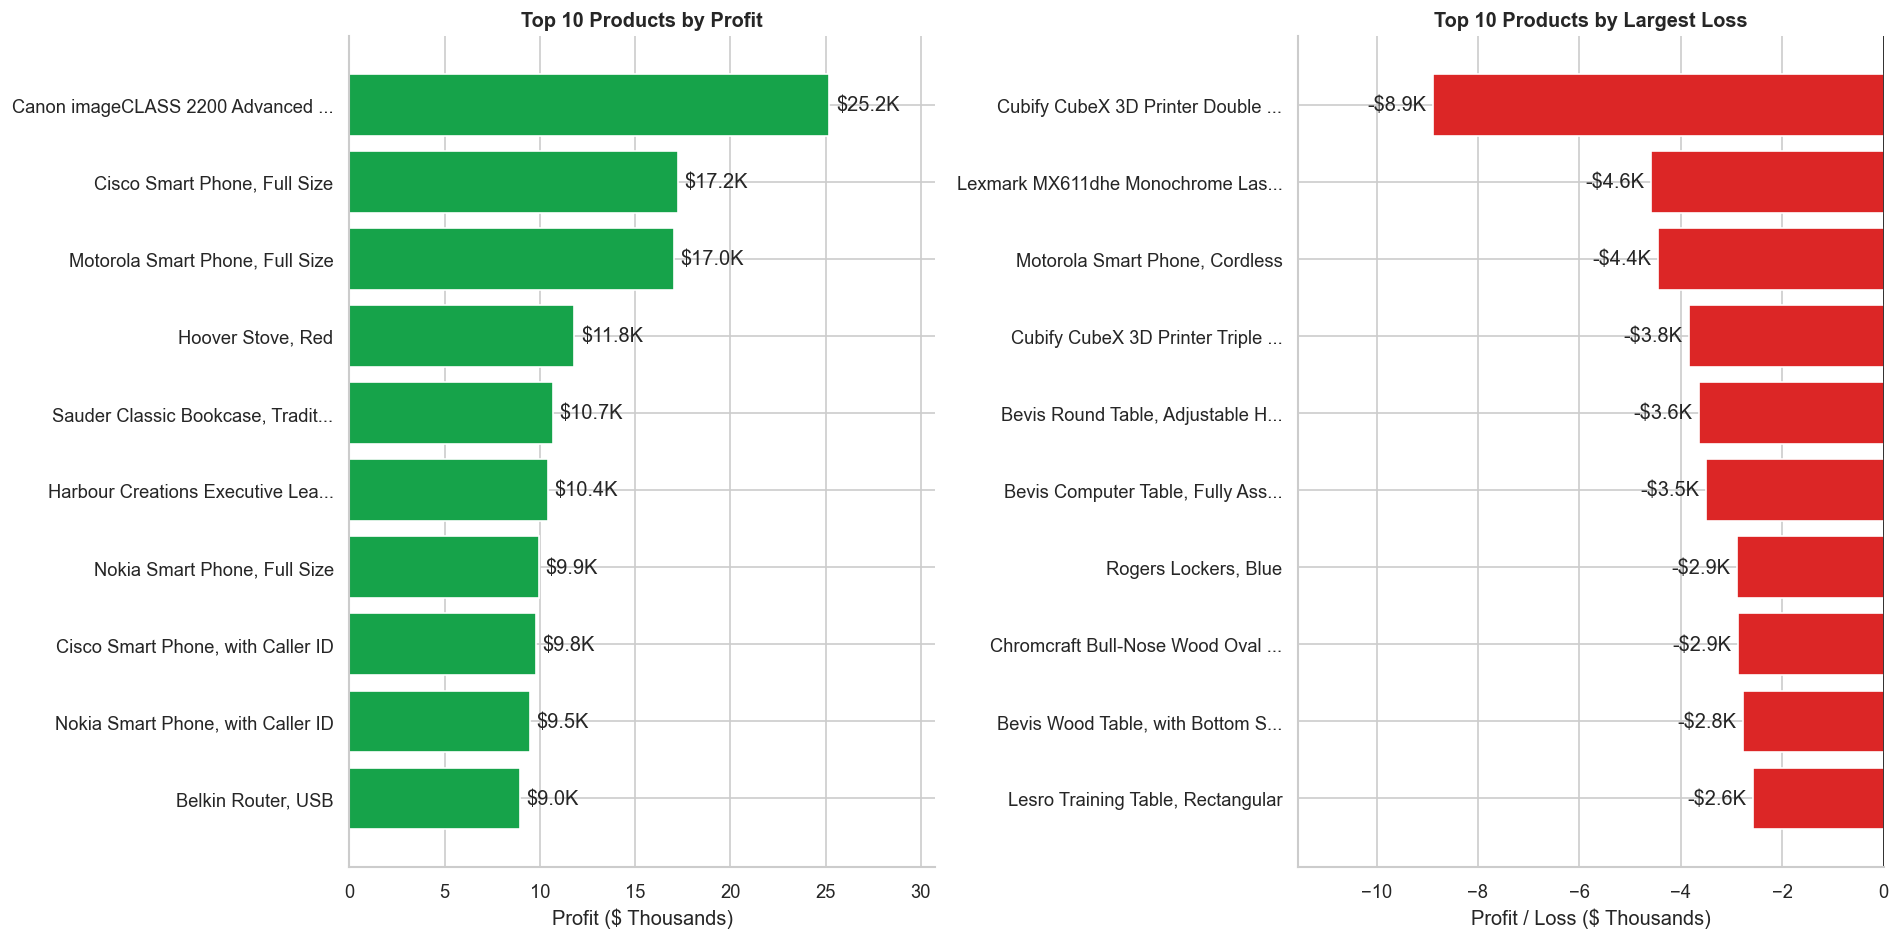

In [19]:
def shorten_product_name(product_name, maximum_length=34):
    if len(product_name) <= maximum_length:
        return product_name

    return product_name[:maximum_length - 3] + "..."


top_profit_chart = (
    top_profit_products
    .sort_values("profit", ascending=True)
    .copy()
)

largest_loss_chart = (
    largest_loss_products
    .sort_values("profit", ascending=False)
    .copy()
)

top_profit_chart["product_label"] = (
    top_profit_chart["product_name"]
    .map(shorten_product_name)
)

largest_loss_chart["product_label"] = (
    largest_loss_chart["product_name"]
    .map(shorten_product_name)
)


fig, axes = plt.subplots(1, 2, figsize=(16, 8))


top_profit_bars = axes[0].barh(
    top_profit_chart["product_label"],
    top_profit_chart["profit"] / 1_000,
    color="#16A34A"
)

axes[0].set_title("Top 10 Products by Profit")
axes[0].set_xlabel("Profit ($ Thousands)")
axes[0].set_ylabel("")

axes[0].bar_label(
    top_profit_bars,
    labels=[
        f"${value / 1_000:,.1f}K"
        for value in top_profit_chart["profit"]
    ],
    padding=4
)


largest_loss_bars = axes[1].barh(
    largest_loss_chart["product_label"],
    largest_loss_chart["profit"] / 1_000,
    color="#DC2626"
)

axes[1].axvline(
    0,
    color="black",
    linewidth=0.9
)

axes[1].set_title("Top 10 Products by Largest Loss")
axes[1].set_xlabel("Profit / Loss ($ Thousands)")
axes[1].set_ylabel("")

axes[1].bar_label(
    largest_loss_bars,
    labels=[
        f"-${abs(value) / 1_000:,.1f}K"
        for value in largest_loss_chart["profit"]
    ],
    padding=4
)


axes[0].margins(x=0.22)
axes[1].margins(x=0.30)

sns.despine()
plt.tight_layout()
plt.show()

### Product Profitability Findings

- **677 products** were loss-making at the aggregate product level.
- These products generated **$2.44 million**, or **19.28% of company revenue**, but produced a combined **$247.84 thousand loss**.
- **Apple Smart Phone, Full Size** was the highest-revenue product at **$86.94 thousand**, but its margin was comparatively low at **6.81%**.
- **Canon imageCLASS 2200 Advanced Copier** generated the highest product profit of **$25.20 thousand**, with a **40.91% margin**, from only five orders.
- **Samsung Smart Phone, Cordless** appeared among the ten highest-revenue products but generated a small aggregate loss.
- **Cubify CubeX 3D Printer Double Head Print** produced the largest product loss of **$8.88 thousand**, with a **-80.00% margin** and **53.33% average line discount**.
- Five of the ten largest-loss products belonged to the **Tables** sub-category.

**Business implication:** Management should prioritize high-revenue loss-making products for transaction-level review, while separately examining heavily discounted Machines and Tables. High discounting is a visible risk factor, but product cost structure and geographic performance must also be evaluated before taking action.

## 6. Discount and Profitability Analysis

### 6.1 Performance by Discount Band

I compare revenue, profit, margin, and loss frequency across business-friendly discount bands. This analysis measures association and does not by itself prove that discounting causes losses.

In [20]:
discount_bins = [
    -0.000001,
    0.00,
    0.10,
    0.20,
    0.30,
    1.00
]

discount_labels = [
    "No Discount",
    "Low (>0% to 10%)",
    "Moderate (>10% to 20%)",
    "High (>20% to 30%)",
    "Very High (>30%)"
]


orders["discount_band"] = pd.cut(
    orders["discount"],
    bins=discount_bins,
    labels=discount_labels,
    include_lowest=True,
    ordered=True
)

if orders["discount_band"].isna().any():
    raise ValueError(
        "Some discount values were not assigned to a discount band."
    )


discount_performance = (
    orders
    .groupby(
        "discount_band",
        observed=True,
        as_index=False
    )
    .agg(
        sales_lines=("row_id", "count"),
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        quantity=("quantity", "sum"),
        average_discount=("discount", "mean"),
        loss_lines=("profit", lambda values: (values < 0).sum())
    )
)

discount_performance["profit_margin"] = (
    discount_performance["profit"]
    / discount_performance["revenue"]
)

discount_performance["loss_line_rate"] = (
    discount_performance["loss_lines"]
    / discount_performance["sales_lines"]
)

discount_performance["revenue_share"] = (
    discount_performance["revenue"]
    / total_revenue
)


discount_display = discount_performance.copy()

discount_display["revenue"] = (
    discount_display["revenue"].map("${:,.2f}".format)
)

discount_display["profit"] = (
    discount_display["profit"].map("${:,.2f}".format)
)

discount_display["average_discount"] = (
    discount_display["average_discount"].map("{:.2%}".format)
)

discount_display["profit_margin"] = (
    discount_display["profit_margin"].map("{:.2%}".format)
)

discount_display["loss_line_rate"] = (
    discount_display["loss_line_rate"].map("{:.2%}".format)
)

discount_display["revenue_share"] = (
    discount_display["revenue_share"].map("{:.2%}".format)
)

discount_display = discount_display.rename(
    columns={
        "discount_band": "Discount Band",
        "sales_lines": "Sales Lines",
        "revenue": "Revenue",
        "profit": "Profit",
        "quantity": "Quantity",
        "average_discount": "Average Discount",
        "loss_lines": "Loss Lines",
        "profit_margin": "Profit Margin",
        "loss_line_rate": "Loss-Line Rate",
        "revenue_share": "Revenue Share"
    }
)

display(discount_display)

,Discount Band,Sales Lines,Revenue,Profit,Quantity,Average Discount,Loss Lines,Profit Margin,Loss-Line Rate,Revenue Share
0,No Discount,29009,"$6,992,410.95","$1,770,695.49",98768,0.00%,0,25.32%,0.00%,55.31%
1,Low (>0% to 10%),4679,"$1,962,620.58","$338,190.30",17607,8.94%,900,17.23%,19.23%,15.52%
2,Moderate (>10% to 20%),6274,"$1,757,261.77","$173,255.93",23394,19.22%,1463,9.86%,23.32%,13.90%
3,High (>20% to 30%),967,"$382,555.19","$-21,155.64",3679,27.36%,599,-5.53%,61.94%,3.03%
4,Very High (>30%),10361,"$1,547,658.76","$-793,529.41",34864,52.52%,9578,-51.27%,92.44%,12.24%


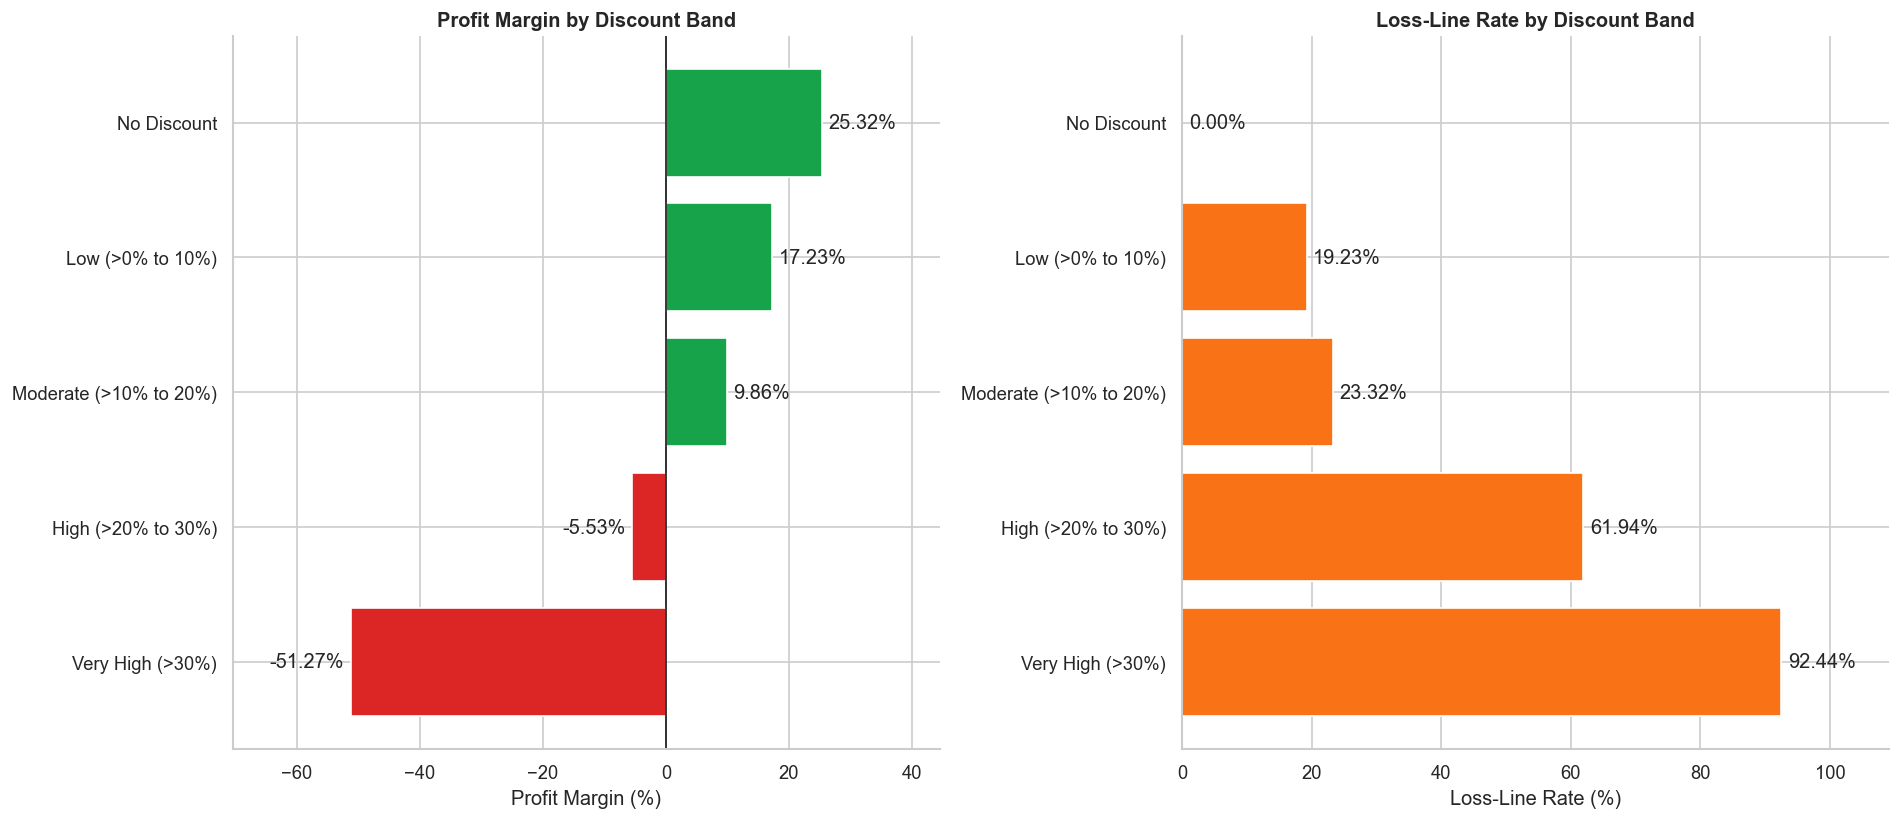

In [21]:
discount_chart_data = (
    discount_performance
    .iloc[::-1]
    .copy()
)

discount_chart_data["discount_band_label"] = (
    discount_chart_data["discount_band"].astype(str)
)

margin_colors = np.where(
    discount_chart_data["profit_margin"] < 0,
    "#DC2626",
    "#16A34A"
)


fig, axes = plt.subplots(1, 2, figsize=(16, 7))


margin_bars = axes[0].barh(
    discount_chart_data["discount_band_label"],
    discount_chart_data["profit_margin"] * 100,
    color=margin_colors
)

axes[0].axvline(
    0,
    color="black",
    linewidth=0.9
)

axes[0].set_title("Profit Margin by Discount Band")
axes[0].set_xlabel("Profit Margin (%)")
axes[0].set_ylabel("")

axes[0].bar_label(
    margin_bars,
    labels=[
        f"{value:.2%}"
        for value in discount_chart_data["profit_margin"]
    ],
    padding=4
)


loss_rate_bars = axes[1].barh(
    discount_chart_data["discount_band_label"],
    discount_chart_data["loss_line_rate"] * 100,
    color="#F97316"
)

axes[1].set_title("Loss-Line Rate by Discount Band")
axes[1].set_xlabel("Loss-Line Rate (%)")
axes[1].set_ylabel("")

axes[1].bar_label(
    loss_rate_bars,
    labels=[
        f"{value:.2%}"
        for value in discount_chart_data["loss_line_rate"]
    ],
    padding=4
)


axes[0].margins(x=0.25)
axes[1].margins(x=0.18)

sns.despine()
plt.tight_layout()
plt.show()

### Discount Findings

- Non-discounted sales generated **55.31% of revenue** and **$1.77 million in profit**, with a **25.32% margin** and no loss-making sales lines.
- Profit margin declined progressively from **17.23%** in the low-discount band to **9.86%** in the moderate-discount band.
- Discounts above **20%** were loss-making in aggregate.
- The very-high-discount band generated **12.24% of revenue** but produced a **$793.53 thousand loss**, with a **-51.27% margin**.
- The loss-line rate increased from **19.23%** in the low-discount band to **92.44%** when discounts exceeded 30%.
- Across all discounted bands combined, the company generated a net loss of approximately **$303.24 thousand**, despite those transactions contributing **44.69% of revenue**.

**Business implication:** Discounts above 20% require stricter approval and profitability review, with immediate attention to discounts above 30%. However, discount policy should be evaluated together with product, market, and cost structure because this descriptive analysis shows association rather than causation.

## 7. Geographic Performance

### 7.1 Market Performance

I compare markets using revenue, profit, margin, order volume, average order value, and returned-order rate.

In [22]:
market_performance = (
    orders
    .groupby("market", as_index=False)
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_key", "nunique"),
        quantity=("quantity", "sum")
    )
)


market_returns = (
    orders.loc[orders["is_returned"]]
    .groupby("market", as_index=False)
    .agg(
        returned_orders=("order_key", "nunique")
    )
)


market_performance = market_performance.merge(
    market_returns,
    on="market",
    how="left",
    validate="one_to_one"
)

market_performance["returned_orders"] = (
    market_performance["returned_orders"]
    .fillna(0)
    .astype(int)
)

market_performance["profit_margin"] = (
    market_performance["profit"]
    / market_performance["revenue"]
)

market_performance["average_order_value"] = (
    market_performance["revenue"]
    / market_performance["orders"]
)

market_performance["return_rate"] = (
    market_performance["returned_orders"]
    / market_performance["orders"]
)

market_performance["revenue_share"] = (
    market_performance["revenue"]
    / total_revenue
)

market_performance = (
    market_performance
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)


market_display = market_performance.copy()

market_display["revenue"] = (
    market_display["revenue"].map("${:,.2f}".format)
)

market_display["profit"] = (
    market_display["profit"].map("${:,.2f}".format)
)

market_display["profit_margin"] = (
    market_display["profit_margin"].map("{:.2%}".format)
)

market_display["average_order_value"] = (
    market_display["average_order_value"]
    .map("${:,.2f}".format)
)

market_display["return_rate"] = (
    market_display["return_rate"].map("{:.2%}".format)
)

market_display["revenue_share"] = (
    market_display["revenue_share"].map("{:.2%}".format)
)

market_display = market_display.rename(
    columns={
        "market": "Market",
        "revenue": "Revenue",
        "profit": "Profit",
        "orders": "Orders",
        "quantity": "Quantity",
        "returned_orders": "Returned Orders",
        "profit_margin": "Profit Margin",
        "average_order_value": "Average Order Value",
        "return_rate": "Return Rate",
        "revenue_share": "Revenue Share"
    }
)

display(market_display)

,Market,Revenue,Profit,Orders,Quantity,Returned Orders,Profit Margin,Average Order Value,Return Rate,Revenue Share
0,Asia Pacific,"$4,042,660.74","$403,176.04",7080,48597,307,9.97%,$571.00,4.34%,31.98%
1,Europe,"$3,287,338.58","$449,550.85",6013,41919,243,13.68%,$546.71,4.04%,26.00%
2,USCA,"$2,364,129.24","$304,215.01",5214,38706,233,12.87%,$453.42,4.47%,18.70%
3,LATAM,"$2,164,605.32","$221,643.64",5144,38526,209,10.24%,$420.80,4.06%,17.12%
4,Africa,"$783,773.37","$88,871.13",2288,10564,87,11.34%,$342.56,3.80%,6.20%


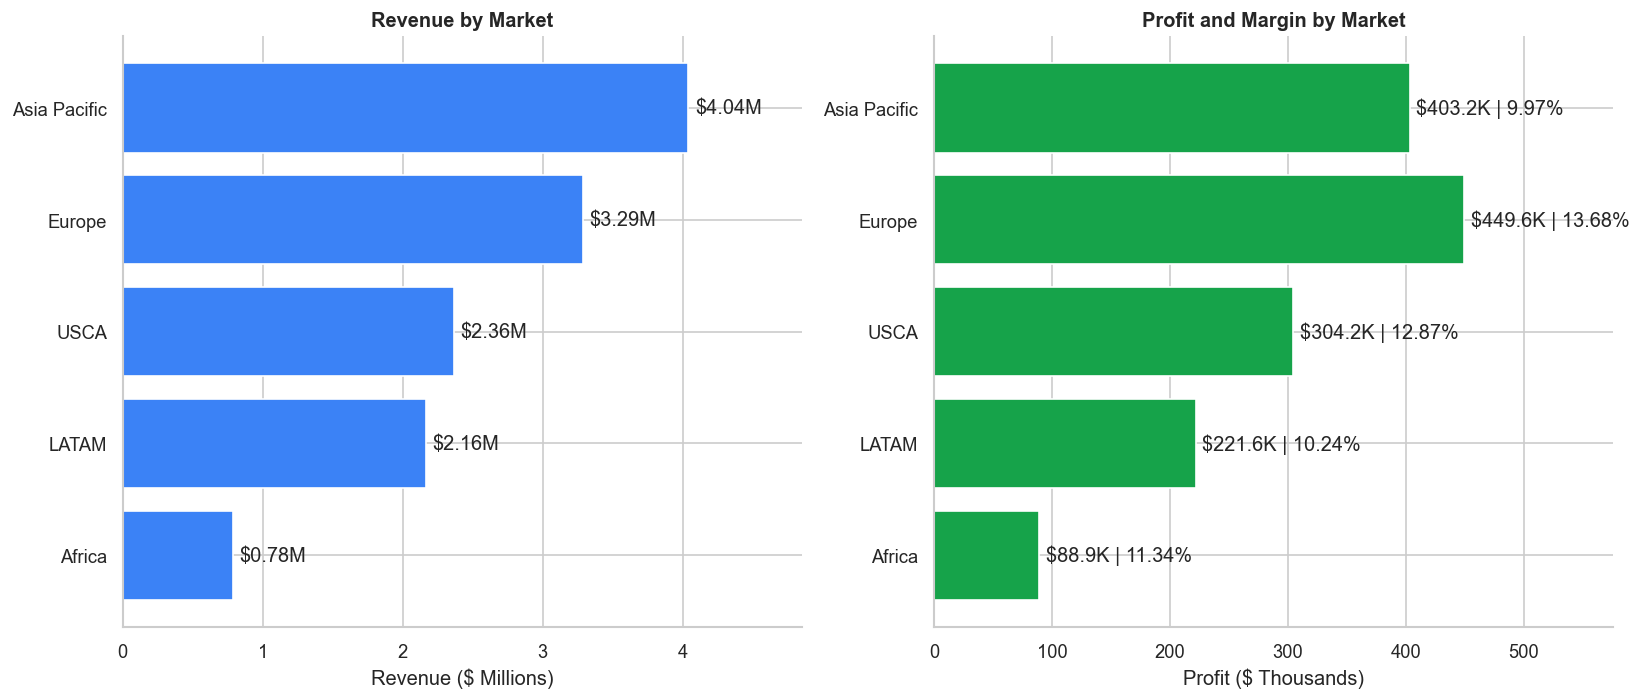

In [23]:
market_chart_data = (
    market_performance
    .sort_values("revenue", ascending=True)
    .copy()
)

market_chart_data["revenue_millions"] = (
    market_chart_data["revenue"] / 1_000_000
)

market_chart_data["profit_thousands"] = (
    market_chart_data["profit"] / 1_000
)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))


revenue_bars = axes[0].barh(
    market_chart_data["market"],
    market_chart_data["revenue_millions"],
    color="#3B82F6"
)

axes[0].set_title("Revenue by Market")
axes[0].set_xlabel("Revenue ($ Millions)")
axes[0].set_ylabel("")

axes[0].bar_label(
    revenue_bars,
    labels=[
        f"${value:.2f}M"
        for value in market_chart_data["revenue_millions"]
    ],
    padding=4
)


profit_bars = axes[1].barh(
    market_chart_data["market"],
    market_chart_data["profit_thousands"],
    color="#16A34A"
)

axes[1].set_title("Profit and Margin by Market")
axes[1].set_xlabel("Profit ($ Thousands)")
axes[1].set_ylabel("")

axes[1].bar_label(
    profit_bars,
    labels=[
        f"${profit:.1f}K | {margin:.2%}"
        for profit, margin in zip(
            market_chart_data["profit_thousands"],
            market_chart_data["profit_margin"]
        )
    ],
    padding=4
)


axes[0].margins(x=0.20)
axes[1].margins(x=0.28)

sns.despine()
plt.tight_layout()
plt.show()

### Market Findings

- **Asia Pacific** was the largest market, contributing **31.98% of revenue**, but its **9.97% margin** was below the company-wide margin of **11.61%**.
- **Europe** generated the highest profit at **$449.55 thousand** and achieved the strongest market margin at **13.68%**.
- **USCA** achieved a healthy **12.87% margin**, but recorded the highest returned-order rate at **4.47%**.
- **LATAM** contributed **17.12% of revenue** with a lower **10.24% margin**.
- **Africa** was the smallest market, contributing **6.20% of revenue**, and recorded the lowest average order value at **$342.56**.

**Business implication:** Europe provides a useful profitability benchmark, while Asia Pacific and LATAM require margin-focused product and discount analysis. USCA requires additional return diagnostics.

### 7.2 Country Performance

I evaluate country-level revenue, profit, margin, orders, discounts, and returned-order rates before identifying the strongest and weakest countries.

In [24]:
country_performance = (
    orders
    .groupby(
        ["market", "country"],
        as_index=False
    )
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_key", "nunique"),
        quantity=("quantity", "sum"),
        average_line_discount=("discount", "mean")
    )
)


country_returns = (
    orders.loc[orders["is_returned"]]
    .groupby(
        ["market", "country"],
        as_index=False
    )
    .agg(
        returned_orders=("order_key", "nunique")
    )
)


country_performance = country_performance.merge(
    country_returns,
    on=["market", "country"],
    how="left",
    validate="one_to_one"
)

country_performance["returned_orders"] = (
    country_performance["returned_orders"]
    .fillna(0)
    .astype(int)
)

country_performance["profit_margin"] = (
    country_performance["profit"]
    / country_performance["revenue"]
)

country_performance["average_order_value"] = (
    country_performance["revenue"]
    / country_performance["orders"]
)

country_performance["return_rate"] = (
    country_performance["returned_orders"]
    / country_performance["orders"]
)

country_performance["profit_status"] = np.select(
    [
        country_performance["profit"] > 0,
        country_performance["profit"] < 0
    ],
    [
        "Profitable",
        "Loss-Making"
    ],
    default="Break-Even"
)


loss_making_countries = country_performance.loc[
    country_performance["profit"] < 0
].copy()


country_summary = pd.DataFrame({
    "Metric": [
        "Countries Analyzed",
        "Profitable Countries",
        "Loss-Making Countries",
        "Break-Even Countries",
        "Revenue from Loss-Making Countries",
        "Combined Loss from Loss-Making Countries"
    ],
    "Value": [
        f"{len(country_performance):,}",
        (
            f"{country_performance['profit_status']
            .eq('Profitable').sum():,}"
        ),
        (
            f"{country_performance['profit_status']
            .eq('Loss-Making').sum():,}"
        ),
        (
            f"{country_performance['profit_status']
            .eq('Break-Even').sum():,}"
        ),
        f"${loss_making_countries['revenue'].sum():,.2f}",
        f"${loss_making_countries['profit'].sum():,.2f}"
    ]
})

display(country_summary)

,Metric,Value
0,Countries Analyzed,165
1,Profitable Countries,134
2,Loss-Making Countries,31
3,Break-Even Countries,0
4,Revenue from Loss-Making Countries,"$1,169,998.04"
5,Combined Loss from Loss-Making Countries,"$-448,093.64"


In [25]:
def format_country_table(dataframe):
    formatted_table = dataframe[
        [
            "country",
            "market",
            "revenue",
            "profit",
            "profit_margin",
            "orders",
            "average_line_discount"
        ]
    ].copy()

    formatted_table["revenue"] = (
        formatted_table["revenue"].map("${:,.2f}".format)
    )

    formatted_table["profit"] = (
        formatted_table["profit"].map("${:,.2f}".format)
    )

    formatted_table["profit_margin"] = (
        formatted_table["profit_margin"].map("{:.2%}".format)
    )

    formatted_table["average_line_discount"] = (
        formatted_table["average_line_discount"]
        .map("{:.2%}".format)
    )

    return formatted_table.rename(
        columns={
            "country": "Country",
            "market": "Market",
            "revenue": "Revenue",
            "profit": "Profit",
            "profit_margin": "Profit Margin",
            "orders": "Orders",
            "average_line_discount": "Average Line Discount"
        }
    )


top_revenue_countries = (
    country_performance
    .nlargest(10, "revenue")
    .copy()
)

top_profit_countries = (
    country_performance
    .nlargest(10, "profit")
    .copy()
)

largest_loss_countries = (
    country_performance
    .nsmallest(10, "profit")
    .copy()
)


print("Top 10 Countries by Revenue")
display(
    format_country_table(top_revenue_countries)
)

print("Top 10 Countries by Profit")
display(
    format_country_table(top_profit_countries)
)

print("Top 10 Countries by Largest Loss")
display(
    format_country_table(largest_loss_countries)
)

Top 10 Countries by Revenue


,Country,Market,Revenue,Profit,Profit Margin,Orders,Average Line Discount
164,United States,USCA,"$2,297,201.07","$286,397.62",12.47%,5009,15.62%
52,Australia,Asia Pacific,"$925,236.91","$103,907.98",11.23%,1419,14.35%
109,France,Europe,"$858,931.65","$109,029.17",12.69%,1473,7.23%
58,China,Asia Pacific,"$700,562.09","$150,683.04",21.51%,925,1.43%
110,Germany,Europe,"$628,136.55","$107,190.38",17.06%,1018,5.71%
154,Mexico,LATAM,"$621,552.81","$102,453.75",16.48%,1322,6.18%
61,India,Asia Pacific,"$589,486.12","$129,050.51",21.89%,783,1.77%
133,United Kingdom,Europe,"$528,576.55","$111,900.01",21.17%,851,6.57%
62,Indonesia,Asia Pacific,"$404,887.67","$15,608.74",3.86%,698,29.73%
138,Brazil,LATAM,"$359,924.85","$29,686.89",8.25%,780,14.62%


Top 10 Countries by Profit


,Country,Market,Revenue,Profit,Profit Margin,Orders,Average Line Discount
164,United States,USCA,"$2,297,201.07","$286,397.62",12.47%,5009,15.62%
58,China,Asia Pacific,"$700,562.09","$150,683.04",21.51%,925,1.43%
61,India,Asia Pacific,"$589,486.12","$129,050.51",21.89%,783,1.77%
133,United Kingdom,Europe,"$528,576.55","$111,900.01",21.17%,851,6.57%
109,France,Europe,"$858,931.65","$109,029.17",12.69%,1473,7.23%
110,Germany,Europe,"$628,136.55","$107,190.38",17.06%,1018,5.71%
52,Australia,Asia Pacific,"$925,236.91","$103,907.98",11.23%,1419,14.35%
154,Mexico,LATAM,"$621,552.81","$102,453.75",16.48%,1322,6.18%
129,Spain,Europe,"$287,146.72","$54,390.10",18.94%,455,3.48%
145,El Salvador,LATAM,"$177,554.91","$42,023.25",23.67%,375,0.39%


Top 10 Countries by Largest Loss


,Country,Market,Revenue,Profit,Profit Margin,Orders,Average Line Discount
91,Turkey,Asia Pacific,"$108,507.90","$-98,447.28",-90.73%,679,60.00%
32,Nigeria,Africa,"$54,350.47","$-80,751.18",-148.57%,429,70.00%
120,Netherlands,Europe,"$77,515.39","$-41,070.48",-52.98%,213,48.18%
151,Honduras,LATAM,"$90,125.70","$-29,482.32",-32.71%,349,40.68%
79,Pakistan,Asia Pacific,"$58,872.90","$-22,446.81",-38.13%,123,44.46%
134,Argentina,LATAM,"$57,511.75","$-18,693.83",-32.50%,191,43.32%
156,Panama,LATAM,"$51,539.88","$-17,723.50",-34.39%,199,40.63%
130,Sweden,Europe,"$30,491.65","$-17,519.61",-57.46%,100,50.79%
81,Philippines,Asia Pacific,"$183,420.66","$-16,128.30",-8.79%,326,34.59%
85,South Korea,Asia Pacific,"$33,125.52","$-12,792.99",-38.62%,82,45.29%


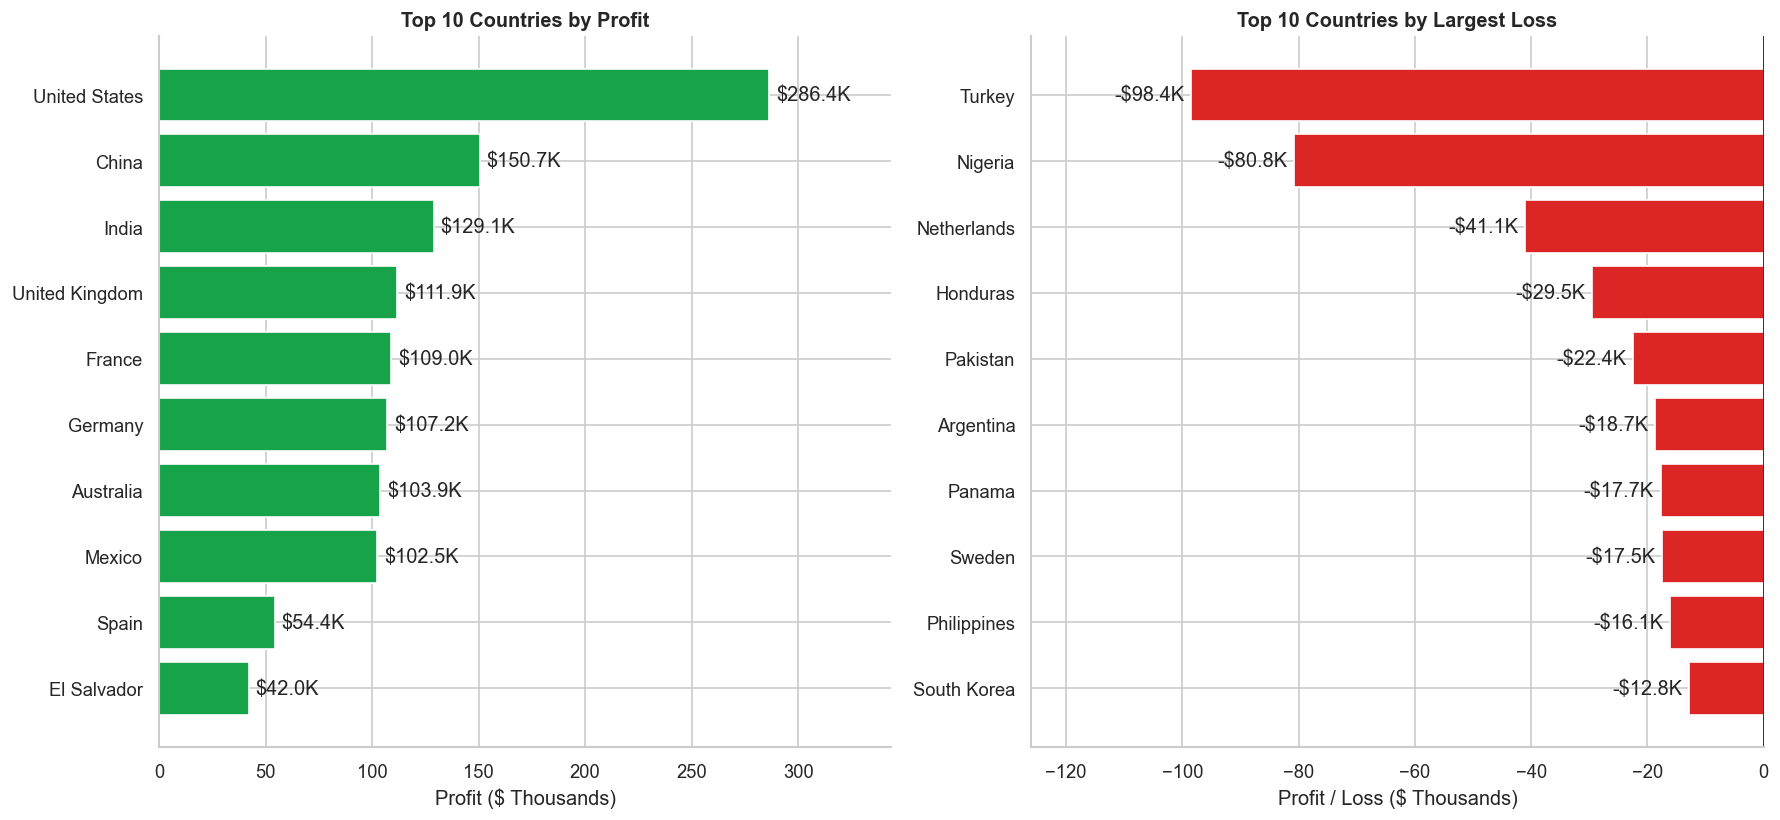

In [26]:
top_country_profit_chart = (
    top_profit_countries
    .sort_values("profit", ascending=True)
    .copy()
)

country_loss_chart = (
    largest_loss_countries
    .sort_values("profit", ascending=False)
    .copy()
)


fig, axes = plt.subplots(1, 2, figsize=(15, 7))


country_profit_bars = axes[0].barh(
    top_country_profit_chart["country"],
    top_country_profit_chart["profit"] / 1_000,
    color="#16A34A"
)

axes[0].set_title("Top 10 Countries by Profit")
axes[0].set_xlabel("Profit ($ Thousands)")
axes[0].set_ylabel("")

axes[0].bar_label(
    country_profit_bars,
    labels=[
        f"${value / 1_000:,.1f}K"
        for value in top_country_profit_chart["profit"]
    ],
    padding=4
)


country_loss_bars = axes[1].barh(
    country_loss_chart["country"],
    country_loss_chart["profit"] / 1_000,
    color="#DC2626"
)

axes[1].axvline(
    0,
    color="black",
    linewidth=0.9
)

axes[1].set_title("Top 10 Countries by Largest Loss")
axes[1].set_xlabel("Profit / Loss ($ Thousands)")
axes[1].set_ylabel("")

axes[1].bar_label(
    country_loss_bars,
    labels=[
        f"-${abs(value) / 1_000:,.1f}K"
        for value in country_loss_chart["profit"]
    ],
    padding=4
)


axes[0].margins(x=0.20)
axes[1].margins(x=0.28)

sns.despine()
plt.tight_layout()
plt.show()

### Country Findings

- **31 of 165 countries** were loss-making at the aggregate level.
- These countries generated **$1.17 million in revenue** but produced a combined **$448.09 thousand loss**.
- The **United States** was the largest country by both revenue and profit, generating **$2.30 million in revenue** and **$286.40 thousand in profit**.
- **China, India, and the United Kingdom** each achieved profit margins above 21%, supported by comparatively low average discounts.
- **Indonesia** ranked among the ten highest-revenue countries but achieved only a **3.86% margin**, with a **29.73% average line discount**.
- **Turkey** generated the largest country loss at **$98.45 thousand**, followed by **Nigeria** at **$80.75 thousand**.
- All ten largest-loss countries recorded average line discounts above 34%, with Turkey at **60%** and Nigeria at **70%**.

**Business implication:** Management should apply country-specific discount and profitability controls, prioritizing Turkey, Nigeria, the Netherlands, and other high-loss markets. The analysis supports targeted intervention, not automatic market exit.

### 7.3 Regional Performance and Manager Context

I identify the highest- and lowest-profit regions and include the available regional-manager mapping to support management follow-up.

In [27]:
region_manager_counts = (
    orders
    .groupby("region")["regional_manager"]
    .nunique()
)

if region_manager_counts.gt(1).any():
    raise ValueError(
        "At least one region is linked to multiple manager labels."
    )


region_performance = (
    orders
    .groupby(
        [
            "market",
            "region",
            "regional_manager",
            "manager_mapping_status"
        ],
        as_index=False
    )
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_key", "nunique"),
        quantity=("quantity", "sum"),
        average_line_discount=("discount", "mean")
    )
)


region_returns = (
    orders.loc[orders["is_returned"]]
    .groupby(
        ["market", "region"],
        as_index=False
    )
    .agg(
        returned_orders=("order_key", "nunique")
    )
)


region_performance = region_performance.merge(
    region_returns,
    on=["market", "region"],
    how="left",
    validate="one_to_one"
)

region_performance["returned_orders"] = (
    region_performance["returned_orders"]
    .fillna(0)
    .astype(int)
)

region_performance["profit_margin"] = (
    region_performance["profit"]
    / region_performance["revenue"]
)

region_performance["return_rate"] = (
    region_performance["returned_orders"]
    / region_performance["orders"]
)


top_profit_regions = (
    region_performance
    .nlargest(5, "profit")
    .copy()
)

largest_loss_regions = (
    region_performance
    .nsmallest(5, "profit")
    .copy()
)


def format_region_table(dataframe):
    formatted_table = dataframe[
        [
            "region",
            "market",
            "regional_manager",
            "revenue",
            "profit",
            "profit_margin",
            "orders",
            "return_rate",
            "average_line_discount"
        ]
    ].copy()

    formatted_table["revenue"] = (
        formatted_table["revenue"].map("${:,.2f}".format)
    )

    formatted_table["profit"] = (
        formatted_table["profit"].map("${:,.2f}".format)
    )

    formatted_table["profit_margin"] = (
        formatted_table["profit_margin"].map("{:.2%}".format)
    )

    formatted_table["return_rate"] = (
        formatted_table["return_rate"].map("{:.2%}".format)
    )

    formatted_table["average_line_discount"] = (
        formatted_table["average_line_discount"]
        .map("{:.2%}".format)
    )

    return formatted_table.rename(
        columns={
            "region": "Region",
            "market": "Market",
            "regional_manager": "Regional Manager",
            "revenue": "Revenue",
            "profit": "Profit",
            "profit_margin": "Profit Margin",
            "orders": "Orders",
            "return_rate": "Return Rate",
            "average_line_discount": "Average Line Discount"
        }
    )


print("Top 5 Regions by Profit")
display(
    format_region_table(top_profit_regions)
)

print("Bottom 5 Regions by Profit")
display(
    format_region_table(largest_loss_regions)
)

Top 5 Regions by Profit


,Region,Market,Regional Manager,Revenue,Profit,Profit Margin,Orders,Return Rate,Average Line Discount
14,Western Europe,Europe,Gilbert Wolff,"$1,731,931.05","$218,433.33",12.61%,2993,4.04%,9.04%
6,Eastern Asia,Asia Pacific,Hadia Bousaid,"$855,059.62","$167,101.62",19.54%,1162,4.56%,4.80%
9,Southern Asia,Asia Pacific,Chandrakant Chaudhri,"$866,573.05","$159,336.18",18.39%,1346,4.31%,5.21%
16,Central America,LATAM,Nicodemo Bautista,"$1,223,100.79","$158,981.81",13.00%,2831,4.13%,10.98%
7,Oceania,Asia Pacific,Kauri Anaru,"$1,100,185.69","$120,089.66",10.92%,1743,4.48%,15.32%


Bottom 5 Regions by Profit


,Region,Market,Regional Manager,Revenue,Profit,Profit Margin,Orders,Return Rate,Average Line Discount
10,Western Asia,Asia Pacific,Kaoru Xun,"$317,106.95","$-53,921.70",-17.00%,1200,4.17%,35.28%
4,Western Africa,Africa,Katlego Akosua,"$173,878.93","$-50,408.25",-28.99%,711,4.08%,43.39%
5,Central Asia,Asia Pacific,Cansu Peynirci,"$19,311.48","$-7,282.06",-37.71%,112,3.57%,41.61%
18,Canada,USCA,Unassigned - Canada mapping unavailable,"$66,928.17","$17,817.39",26.62%,205,2.93%,0.00%
8,Southeastern Asia,Asia Pacific,Preecha Metharom,"$884,423.95","$17,852.34",2.02%,1517,4.22%,27.21%


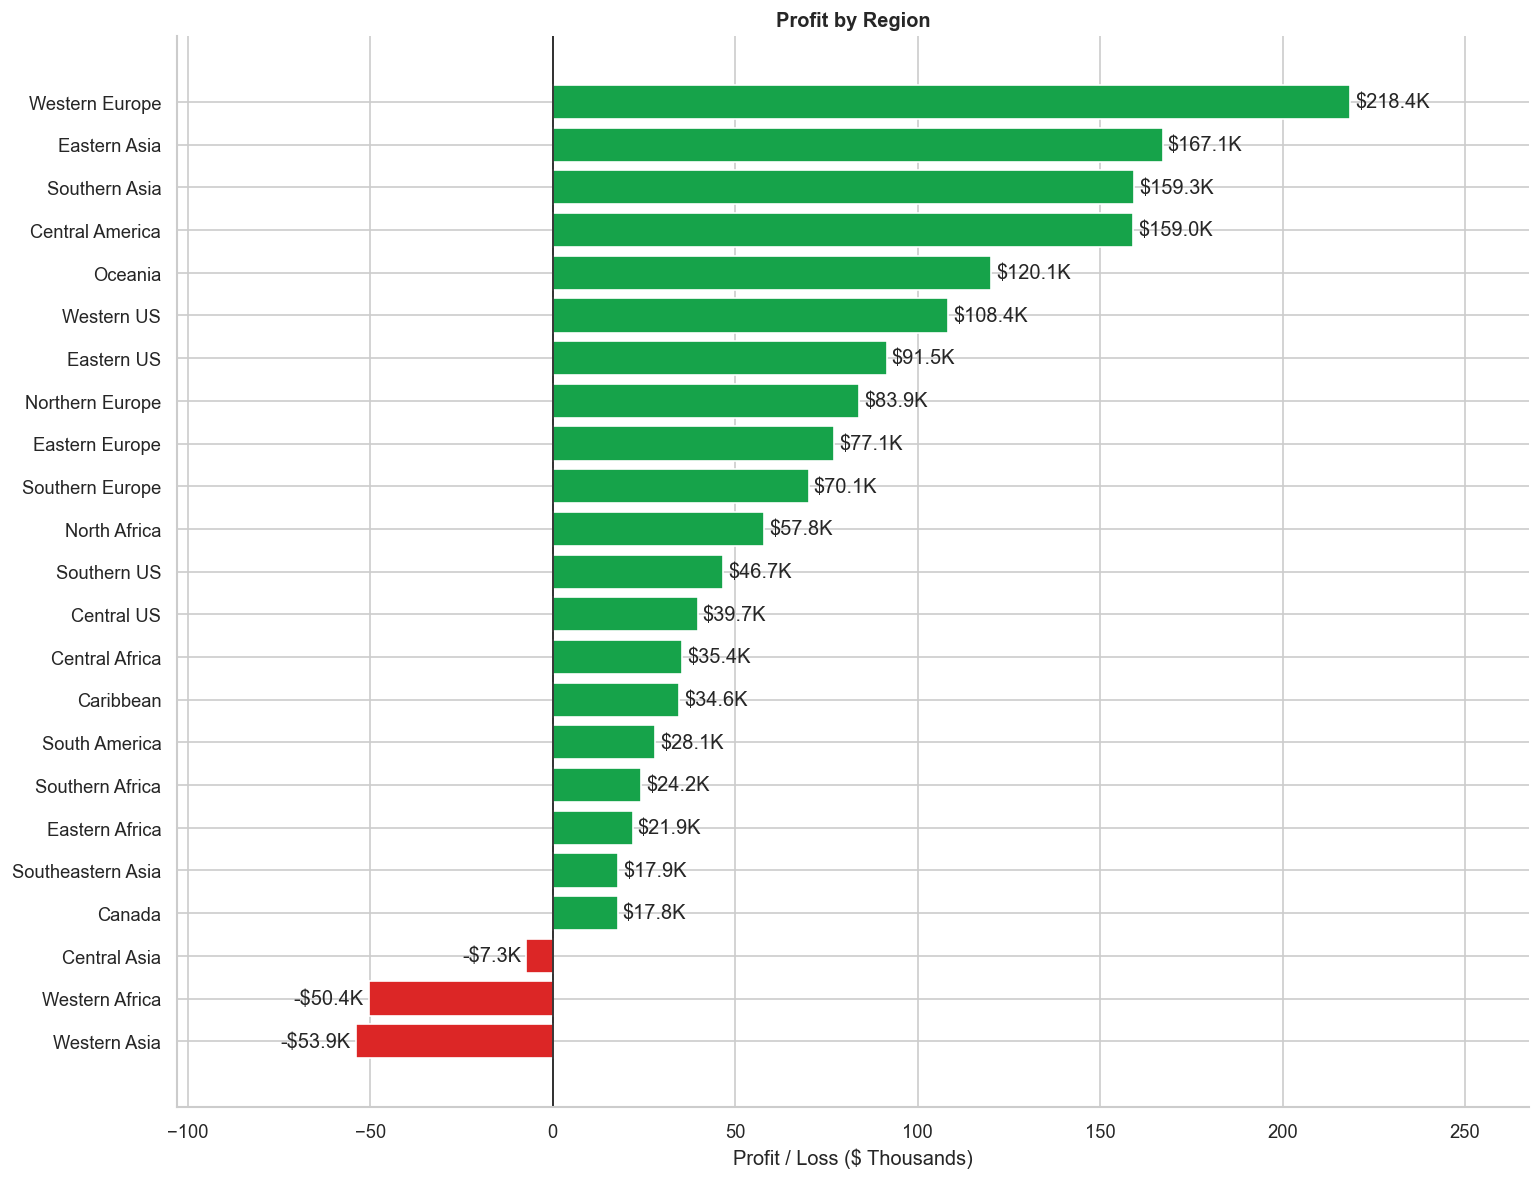

In [28]:
region_profit_chart = (
    region_performance
    .sort_values("profit", ascending=True)
    .copy()
)

region_colors = np.where(
    region_profit_chart["profit"] < 0,
    "#DC2626",
    "#16A34A"
)


fig, axis = plt.subplots(figsize=(13, 10))

region_bars = axis.barh(
    region_profit_chart["region"],
    region_profit_chart["profit"] / 1_000,
    color=region_colors
)

axis.axvline(
    0,
    color="black",
    linewidth=0.9
)

axis.set_title("Profit by Region")
axis.set_xlabel("Profit / Loss ($ Thousands)")
axis.set_ylabel("")

axis.bar_label(
    region_bars,
    labels=[
        (
            f"-${abs(value) / 1_000:,.1f}K"
            if value < 0
            else f"${value / 1_000:,.1f}K"
        )
        for value in region_profit_chart["profit"]
    ],
    padding=3
)

axis.margins(x=0.18)

sns.despine()
plt.tight_layout()
plt.show()

### Regional Findings

- **Western Europe** generated the highest regional profit at **$218.43 thousand**.
- **Eastern Asia** and **Southern Asia** achieved strong margins of **19.54%** and **18.39%**, respectively.
- **Western Asia, Western Africa, and Central Asia** were the only aggregate loss-making regions.
- These three regions recorded average line discounts between **35.28% and 43.39%**.
- **Southeastern Asia** generated substantial revenue of **$884.42 thousand**, but produced only **$17.85 thousand in profit**, resulting in a weak **2.02% margin**.
- Canada was profitable with a **26.62% margin**, but its regional-manager mapping remained unavailable in the source data.

**Business implication:** Western Asia, Western Africa, Central Asia, and Southeastern Asia require targeted discount and product-mix reviews. Regional-manager details can support operational follow-up, but the dataset does not establish that managers caused regional performance.

## 8. Customer Analytics

### 8.1 Customer-Level Performance

I aggregate sales-line data to one record per validated customer to measure revenue, profit, order frequency, average order value, product diversity, and return behaviour.

In [29]:
customer_performance = (
    orders
    .groupby(
        [
            "customer_key",
            "customer_name",
            "segment"
        ],
        as_index=False
    )
    .agg(
        first_order_date=("order_date", "min"),
        last_order_date=("order_date", "max"),
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_key", "nunique"),
        quantity=("quantity", "sum"),
        unique_products=("product_id", "nunique")
    )
)


customer_returns = (
    orders.loc[orders["is_returned"]]
    .groupby(
        "customer_key",
        as_index=False
    )
    .agg(
        returned_orders=("order_key", "nunique")
    )
)


customer_performance = customer_performance.merge(
    customer_returns,
    on="customer_key",
    how="left",
    validate="one_to_one"
)

customer_performance["returned_orders"] = (
    customer_performance["returned_orders"]
    .fillna(0)
    .astype(int)
)

customer_performance["profit_margin"] = (
    customer_performance["profit"]
    / customer_performance["revenue"]
)

customer_performance["average_order_value"] = (
    customer_performance["revenue"]
    / customer_performance["orders"]
)

customer_performance["return_rate"] = (
    customer_performance["returned_orders"]
    / customer_performance["orders"]
)

customer_performance["customer_type"] = np.where(
    customer_performance["orders"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)


customer_frequency_summary = pd.DataFrame({
    "Metric": [
        "Customers",
        "Repeat Customers",
        "One-Time Customers",
        "Minimum Orders per Customer",
        "Median Orders per Customer",
        "Maximum Orders per Customer"
    ],
    "Value": [
        f"{len(customer_performance):,}",
        (
            f"{customer_performance['customer_type']
            .eq('Repeat Customer').sum():,}"
        ),
        (
            f"{customer_performance['customer_type']
            .eq('One-Time Customer').sum():,}"
        ),
        f"{customer_performance['orders'].min():,}",
        f"{customer_performance['orders'].median():,.1f}",
        f"{customer_performance['orders'].max():,}"
    ]
})

display(customer_frequency_summary)

,Metric,Value
0,Customers,796
1,Repeat Customers,795
2,One-Time Customers,1
3,Minimum Orders per Customer,1
4,Median Orders per Customer,32.0
5,Maximum Orders per Customer,47


### 8.2 Repeat and One-Time Customer Comparison

I compare repeat and one-time customers descriptively. Because the dataset contains only one one-time customer, I do not treat the comparison as statistically representative.

In [30]:
customer_type_performance = (
    customer_performance
    .groupby(
        "customer_type",
        as_index=False
    )
    .agg(
        customers=("customer_key", "nunique"),
        revenue=("revenue", "sum"),
        profit=("profit", "sum"),
        orders=("orders", "sum")
    )
)

customer_type_performance["revenue_share"] = (
    customer_type_performance["revenue"]
    / total_revenue
)

customer_type_performance["profit_margin"] = (
    customer_type_performance["profit"]
    / customer_type_performance["revenue"]
)

customer_type_performance["average_order_value"] = (
    customer_type_performance["revenue"]
    / customer_type_performance["orders"]
)

customer_type_performance["average_revenue_per_customer"] = (
    customer_type_performance["revenue"]
    / customer_type_performance["customers"]
)


customer_type_display = customer_type_performance.copy()

for column in [
    "revenue",
    "profit",
    "average_order_value",
    "average_revenue_per_customer"
]:
    customer_type_display[column] = (
        customer_type_display[column]
        .map("${:,.2f}".format)
    )

for column in [
    "revenue_share",
    "profit_margin"
]:
    customer_type_display[column] = (
        customer_type_display[column]
        .map("{:.2%}".format)
    )

customer_type_display = customer_type_display.rename(
    columns={
        "customer_type": "Customer Type",
        "customers": "Customers",
        "revenue": "Revenue",
        "profit": "Profit",
        "orders": "Orders",
        "revenue_share": "Revenue Share",
        "profit_margin": "Profit Margin",
        "average_order_value": "Average Order Value",
        "average_revenue_per_customer": (
            "Average Revenue per Customer"
        )
    }
)

display(customer_type_display)


print("One-Time Customer Record")

display(
    customer_performance.loc[
        customer_performance["customer_type"]
        .eq("One-Time Customer"),
        [
            "customer_name",
            "segment",
            "orders",
            "revenue",
            "profit",
            "average_order_value"
        ]
    ]
)

,Customer Type,Customers,Revenue,Profit,Orders,Revenue Share,Profit Margin,Average Order Value,Average Revenue per Customer
0,One-Time Customer,1,"$1,401.70",$-824.74,1,0.01%,-58.84%,"$1,401.70","$1,401.70"
1,Repeat Customer,795,"$12,641,105.55","$1,468,281.41",25738,99.99%,11.62%,$491.15,"$15,900.76"


One-Time Customer Record


,customer_name,segment,orders,revenue,profit,average_order_value
414,Kai Rey,Home Office,1,"1,401.70",-824.74,"1,401.70"


### Repeat-Customer Findings and Limitation

- **795 of 796 customers** were repeat customers, resulting in a **99.87% repeat-customer rate**.
- Repeat customers generated **99.99% of total revenue** and achieved an **11.62% aggregate profit margin**.
- The dataset contained only one one-time customer, **Kai Rey**, associated with one order, **$1,401.70 in revenue**, and an **$824.74 loss**.
- A single one-time customer is not a sufficient comparison group for reliable behavioural or statistical conclusions.

**Analytical decision:** I report the descriptive values but do not claim that repeat customers are inherently more profitable than one-time customers. New-versus-returning order revenue will be analyzed separately using each customer's first purchase date.

### 8.3 Top and Bottom Customer Performance

I rank customers by revenue, profit, and absolute loss to distinguish high-value relationships from high-sales but unprofitable relationships.

In [31]:
def format_customer_table(dataframe):
    formatted_table = dataframe[
        [
            "customer_name",
            "segment",
            "revenue",
            "profit",
            "profit_margin",
            "orders",
            "average_order_value",
            "return_rate"
        ]
    ].copy()

    formatted_table["revenue"] = (
        formatted_table["revenue"].map("${:,.2f}".format)
    )

    formatted_table["profit"] = (
        formatted_table["profit"].map("${:,.2f}".format)
    )

    formatted_table["profit_margin"] = (
        formatted_table["profit_margin"].map("{:.2%}".format)
    )

    formatted_table["average_order_value"] = (
        formatted_table["average_order_value"]
        .map("${:,.2f}".format)
    )

    formatted_table["return_rate"] = (
        formatted_table["return_rate"].map("{:.2%}".format)
    )

    return formatted_table.rename(
        columns={
            "customer_name": "Customer",
            "segment": "Segment",
            "revenue": "Revenue",
            "profit": "Profit",
            "profit_margin": "Profit Margin",
            "orders": "Orders",
            "average_order_value": "Average Order Value",
            "return_rate": "Return Rate"
        }
    )


top_revenue_customers = (
    customer_performance
    .nlargest(10, "revenue")
    .copy()
)

top_profit_customers = (
    customer_performance
    .nlargest(10, "profit")
    .copy()
)

largest_loss_customers = (
    customer_performance
    .nsmallest(10, "profit")
    .copy()
)


print("Top 10 Customers by Revenue")
display(
    format_customer_table(top_revenue_customers)
)

print("Top 10 Customers by Profit")
display(
    format_customer_table(top_profit_customers)
)

print("Top 10 Customers by Largest Loss")
display(
    format_customer_table(largest_loss_customers)
)

Top 10 Customers by Revenue


,Customer,Segment,Revenue,Profit,Profit Margin,Orders,Average Order Value,Return Rate
759,Tom Ashbrook,Home Office,"$40,488.09","$6,312.01",15.59%,29,"$1,396.14",0.00%
732,Tamara Chand,Corporate,"$37,457.34","$8,672.90",23.15%,36,"$1,040.48",2.78%
313,Greg Tran,Consumer,"$35,550.97","$5,214.11",14.67%,34,"$1,045.62",14.71%
157,Christopher Conant,Consumer,"$35,187.09","$5,603.33",15.92%,39,$902.23,0.00%
688,Sean Miller,Home Office,"$35,170.97",$-409.72,-1.16%,28,"$1,256.11",0.00%
73,Bart Watters,Corporate,"$32,310.46","$3,595.87",11.13%,45,$718.01,0.00%
559,Natalie Fritzler,Consumer,"$31,781.29","$1,542.87",4.85%,43,$739.10,4.65%
290,Fred Hopkins,Corporate,"$30,400.69","$4,609.30",15.16%,39,$779.50,5.13%
347,Jane Waco,Corporate,"$30,288.46","$6,265.85",20.69%,40,$757.21,7.50%
335,Hunter Lopez,Consumer,"$30,243.60","$7,816.57",25.85%,24,"$1,260.15",0.00%


Top 10 Customers by Profit


,Customer,Segment,Revenue,Profit,Profit Margin,Orders,Average Order Value,Return Rate
732,Tamara Chand,Corporate,"$37,457.34","$8,672.90",23.15%,36,"$1,040.48",2.78%
624,Raymond Buch,Consumer,"$29,602.16","$8,453.05",28.56%,29,"$1,020.76",3.45%
673,Sanjit Chand,Consumer,"$26,521.13","$8,205.37",30.94%,35,$757.75,5.71%
335,Hunter Lopez,Consumer,"$30,243.60","$7,816.57",25.85%,24,"$1,260.15",0.00%
88,Bill Eplett,Home Office,"$28,479.17","$7,410.01",26.02%,42,$678.08,2.38%
323,Harry Marie,Corporate,"$28,476.95","$6,958.26",24.43%,41,$694.56,7.32%
728,Susan Pistek,Consumer,"$29,020.60","$6,484.41",22.34%,32,$906.89,3.12%
543,Mike Gockenbach,Consumer,"$23,377.06","$6,458.64",27.63%,27,$865.82,11.11%
6,Adrian Barton,Consumer,"$25,123.19","$6,417.27",25.54%,40,$628.08,2.50%
759,Tom Ashbrook,Home Office,"$40,488.09","$6,312.01",15.59%,29,"$1,396.14",0.00%


Top 10 Customers by Largest Loss


,Customer,Segment,Revenue,Profit,Profit Margin,Orders,Average Order Value,Return Rate
166,Cindy Stewart,Consumer,"$13,429.77","$-6,151.53",-45.81%,23,$583.90,0.00%
479,Luke Foster,Consumer,"$13,421.29","$-3,644.33",-27.15%,27,$497.08,3.70%
308,Grant Thornton,Corporate,"$20,225.37","$-3,577.93",-17.69%,27,$749.09,0.00%
120,Candace McMahon,Corporate,"$14,794.68","$-2,798.81",-18.92%,28,$528.38,7.14%
704,Skye Norling,Home Office,"$14,218.82","$-2,638.00",-18.55%,31,$458.67,6.45%
222,Denise Monton,Corporate,"$22,053.31","$-2,597.79",-11.78%,32,$689.17,3.12%
695,Sharelle Roach,Home Office,"$13,002.46","$-2,551.18",-19.62%,24,$541.77,4.17%
207,David Bremer,Corporate,"$6,273.82","$-2,270.71",-36.19%,20,$313.69,10.00%
686,Sean Braxton,Corporate,"$20,513.94","$-1,896.98",-9.25%,26,$789.00,0.00%
406,Julie Creighton,Corporate,"$14,994.05","$-1,889.09",-12.60%,34,$441.00,11.76%


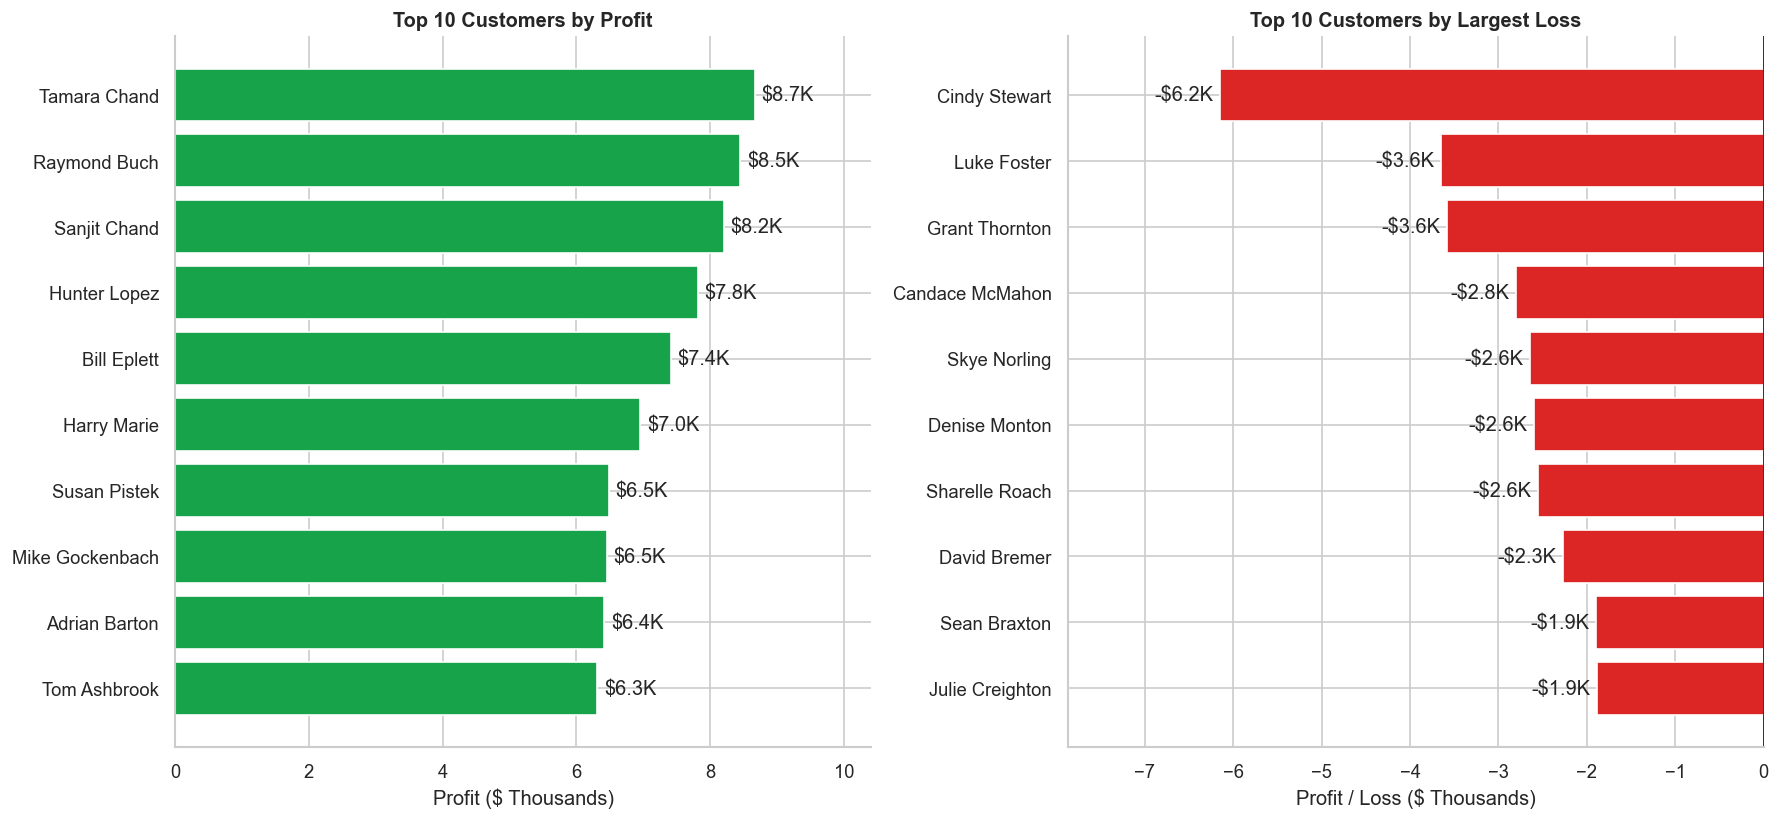

In [32]:
top_customer_profit_chart = (
    top_profit_customers
    .sort_values("profit", ascending=True)
    .copy()
)

customer_loss_chart = (
    largest_loss_customers
    .sort_values("profit", ascending=False)
    .copy()
)


fig, axes = plt.subplots(1, 2, figsize=(15, 7))


customer_profit_bars = axes[0].barh(
    top_customer_profit_chart["customer_name"],
    top_customer_profit_chart["profit"] / 1_000,
    color="#16A34A"
)

axes[0].set_title("Top 10 Customers by Profit")
axes[0].set_xlabel("Profit ($ Thousands)")
axes[0].set_ylabel("")

axes[0].bar_label(
    customer_profit_bars,
    labels=[
        f"${value / 1_000:,.1f}K"
        for value in top_customer_profit_chart["profit"]
    ],
    padding=4
)


customer_loss_bars = axes[1].barh(
    customer_loss_chart["customer_name"],
    customer_loss_chart["profit"] / 1_000,
    color="#DC2626"
)

axes[1].axvline(
    0,
    color="black",
    linewidth=0.9
)

axes[1].set_title("Top 10 Customers by Largest Loss")
axes[1].set_xlabel("Profit / Loss ($ Thousands)")
axes[1].set_ylabel("")

axes[1].bar_label(
    customer_loss_bars,
    labels=[
        f"-${abs(value) / 1_000:,.1f}K"
        for value in customer_loss_chart["profit"]
    ],
    padding=4
)


axes[0].margins(x=0.20)
axes[1].margins(x=0.28)

sns.despine()
plt.tight_layout()
plt.show()

### Customer Performance Findings

- **Tom Ashbrook** was the highest-revenue customer, generating **$40.49 thousand in revenue** and **$6.31 thousand in profit**.
- **Tamara Chand** was the highest-profit customer, generating **$8.67 thousand in profit** with a **23.15% margin**.
- **Sean Miller** ranked among the five highest-revenue customers but generated an aggregate **$409.72 loss**.
- **Greg Tran** was a high-revenue customer with a comparatively high **14.71% returned-order rate**.
- **Cindy Stewart** generated the largest customer-level loss of **$6.15 thousand**, with a **-45.81% margin**.
- High revenue alone does not reliably indicate customer value; profit, margin, order frequency, and returns must be evaluated together.

**Business implication:** Management should protect high-profit customer relationships while reviewing pricing and product mix for high-revenue loss-making customers. Return behaviour should be investigated separately before changing customer strategy.

### 8.4 New and Returning Customer Revenue

I classify each analytical order using the customer's first observed purchase date.

- **New Customer Revenue:** Revenue from orders placed on the customer's first observed order date.
- **Returning Customer Revenue:** Revenue from orders placed after the customer's first observed order date.
- **Counting note:** Customer counts across the two order types are non-additive. A customer contributes to New Customer Revenue on the first observed purchase date and can also contribute to Returning Customer Revenue through later orders.
  
“New” means new within the 2012–2015 dataset observation window. The data does not confirm whether a customer purchased before 2012.

In [33]:
order_level = (
    orders
    .groupby(
        [
            "order_key",
            "customer_key",
            "customer_name",
            "order_date"
        ],
        as_index=False
    )
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        quantity=("quantity", "sum")
    )
)

if len(order_level) != total_orders:
    raise ValueError(
        "The order-level table does not match the validated order count."
    )


order_level["first_observed_order_date"] = (
    order_level
    .groupby("customer_key")["order_date"]
    .transform("min")
)

order_level["customer_order_type"] = np.where(
    order_level["order_date"].eq(
        order_level["first_observed_order_date"]
    ),
    "New Customer Revenue",
    "Returning Customer Revenue"
)


new_returning_performance = (
    order_level
    .groupby(
        "customer_order_type",
        as_index=False
    )
    .agg(
        customers=("customer_key", "nunique"),
        orders=("order_key", "nunique"),
        revenue=("revenue", "sum"),
        profit=("profit", "sum")
    )
)

new_returning_performance["revenue_share"] = (
    new_returning_performance["revenue"]
    / total_revenue
)

new_returning_performance["profit_margin"] = (
    new_returning_performance["profit"]
    / new_returning_performance["revenue"]
)

new_returning_performance["average_order_value"] = (
    new_returning_performance["revenue"]
    / new_returning_performance["orders"]
)


new_returning_display = new_returning_performance.copy()

for column in [
    "revenue",
    "profit",
    "average_order_value"
]:
    new_returning_display[column] = (
        new_returning_display[column]
        .map("${:,.2f}".format)
    )

for column in [
    "revenue_share",
    "profit_margin"
]:
    new_returning_display[column] = (
        new_returning_display[column]
        .map("{:.2%}".format)
    )

new_returning_display = new_returning_display.rename(
    columns={
        "customer_order_type": "Customer Order Type",
        "customers": "Customers",
        "orders": "Orders",
        "revenue": "Revenue",
        "profit": "Profit",
        "revenue_share": "Revenue Share",
        "profit_margin": "Profit Margin",
        "average_order_value": "Average Order Value"
    }
)

display(new_returning_display)

,Customer Order Type,Customers,Orders,Revenue,Profit,Revenue Share,Profit Margin,Average Order Value
0,New Customer Revenue,796,810,"$396,684.39","$35,023.90",3.14%,8.83%,$489.73
1,Returning Customer Revenue,795,24929,"$12,245,822.86","$1,432,432.77",96.86%,11.70%,$491.23


### New and Returning Revenue Findings

- First-observed-date orders generated **$396.68 thousand**, representing **3.14% of total revenue**.
- Orders placed after the first observed customer date generated **$12.25 million**, representing **96.86% of total revenue**.
- Returning-customer orders achieved an **11.70% margin**, compared with **8.83% for first-observed-date orders**.
- Average order value was similar: **$489.73** for new-customer revenue and **$491.23** for returning-customer revenue.
- The result indicates that company revenue within the available period depended heavily on continued customer purchasing rather than first-observed purchases.

**Analytical limitation:** The dataset begins in 2012 and does not contain pre-2012 purchase history. Therefore, “new customer” means first observed in this dataset, not necessarily a customer's first-ever purchase.

### 8.5 RFM Customer Segmentation

I segment customers using Recency, Frequency, and Monetary value as of the day after the latest order date in the dataset.

- **Recency:** Days since the customer's last observed order
- **Frequency:** Number of unique analytical orders
- **Monetary:** Total customer revenue

Customers receive scores from 1 to 5. A higher score represents more recent activity, higher purchase frequency, or higher monetary value.

In [34]:
rfm_snapshot_date = (
    orders["order_date"].max()
    + pd.Timedelta(days=1)
)


rfm = customer_performance[
    [
        "customer_key",
        "customer_name",
        "segment",
        "last_order_date",
        "orders",
        "revenue",
        "profit"
    ]
].copy()

rfm["recency_days"] = (
    rfm_snapshot_date
    - rfm["last_order_date"]
).dt.days

rfm["frequency"] = rfm["orders"]
rfm["monetary"] = rfm["revenue"]


def create_percentile_score(series, higher_is_better=True):
    percentile_rank = series.rank(
        method="average",
        pct=True
    )

    if higher_is_better:
        score_labels = [1, 2, 3, 4, 5]
    else:
        score_labels = [5, 4, 3, 2, 1]

    return pd.cut(
        percentile_rank,
        bins=[0.00, 0.20, 0.40, 0.60, 0.80, 1.00],
        labels=score_labels,
        include_lowest=True
    ).astype(int)


rfm["recency_score"] = create_percentile_score(
    rfm["recency_days"],
    higher_is_better=False
)

rfm["frequency_score"] = create_percentile_score(
    rfm["frequency"],
    higher_is_better=True
)

rfm["monetary_score"] = create_percentile_score(
    rfm["monetary"],
    higher_is_better=True
)

rfm["rfm_total_score"] = (
    rfm["recency_score"]
    + rfm["frequency_score"]
    + rfm["monetary_score"]
)


rfm_validation = pd.DataFrame({
    "Metric": [
        "RFM Snapshot Date",
        "Customers Scored",
        "Minimum Recency Days",
        "Maximum Recency Days",
        "Minimum RFM Total Score",
        "Maximum RFM Total Score",
        "Missing RFM Scores"
    ],
    "Value": [
        rfm_snapshot_date.strftime("%Y-%m-%d"),
        f"{len(rfm):,}",
        f"{rfm['recency_days'].min():,}",
        f"{rfm['recency_days'].max():,}",
        f"{rfm['rfm_total_score'].min():,}",
        f"{rfm['rfm_total_score'].max():,}",
        f"{rfm[
            ['recency_score', 'frequency_score', 'monetary_score']
        ].isna().sum().sum():,}"
    ]
})

display(rfm_validation)

,Metric,Value
0,RFM Snapshot Date,2016-01-01
1,Customers Scored,796
2,Minimum Recency Days,1
3,Maximum Recency Days,587
4,Minimum RFM Total Score,3
5,Maximum RFM Total Score,15
6,Missing RFM Scores,0


#### RFM Segment Rules

I apply explicit segment rules so that each customer assignment is reproducible and explainable.

- **Champions:** Recent, frequent, and high-spending customers
- **Loyal High-Value:** Strong frequency and monetary value with acceptable recency
- **Recent High Spenders:** Recent and high-spending customers who are not yet highly frequent
- **Potential Loyalists:** Recent customers with moderate frequency
- **At Risk:** Previously frequent customers who have not purchased recently
- **Hibernating:** Infrequent customers with low recency
- **Needs Attention:** Customers not covered by the priority groups above

In [35]:
rfm_segment_conditions = [
    (
        rfm["recency_score"].ge(4)
        & rfm["frequency_score"].ge(4)
        & rfm["monetary_score"].ge(4)
    ),
    (
        rfm["recency_score"].ge(3)
        & rfm["frequency_score"].ge(4)
        & rfm["monetary_score"].ge(3)
    ),
    (
        rfm["recency_score"].ge(4)
        & rfm["monetary_score"].ge(4)
    ),
    (
        rfm["recency_score"].ge(4)
        & rfm["frequency_score"].between(2, 3)
    ),
    (
        rfm["recency_score"].le(2)
        & rfm["frequency_score"].ge(4)
    ),
    (
        rfm["recency_score"].le(2)
        & rfm["frequency_score"].le(2)
    )
]

rfm_segment_labels = [
    "Champions",
    "Loyal High-Value",
    "Recent High Spenders",
    "Potential Loyalists",
    "At Risk",
    "Hibernating"
]


rfm["rfm_segment"] = np.select(
    rfm_segment_conditions,
    rfm_segment_labels,
    default="Needs Attention"
)


rfm_segment_performance = (
    rfm
    .groupby(
        "rfm_segment",
        as_index=False
    )
    .agg(
        customers=("customer_key", "nunique"),
        revenue=("revenue", "sum"),
        profit=("profit", "sum"),
        average_recency_days=("recency_days", "mean"),
        average_orders=("frequency", "mean")
    )
)

rfm_segment_performance["customer_share"] = (
    rfm_segment_performance["customers"]
    / len(rfm)
)

rfm_segment_performance["revenue_share"] = (
    rfm_segment_performance["revenue"]
    / total_revenue
)

rfm_segment_performance["profit_margin"] = (
    rfm_segment_performance["profit"]
    / rfm_segment_performance["revenue"]
)

rfm_segment_performance = (
    rfm_segment_performance
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)


rfm_segment_display = rfm_segment_performance.copy()

rfm_segment_display["revenue"] = (
    rfm_segment_display["revenue"].map("${:,.2f}".format)
)

rfm_segment_display["profit"] = (
    rfm_segment_display["profit"].map("${:,.2f}".format)
)

rfm_segment_display["customer_share"] = (
    rfm_segment_display["customer_share"].map("{:.2%}".format)
)

rfm_segment_display["revenue_share"] = (
    rfm_segment_display["revenue_share"].map("{:.2%}".format)
)

rfm_segment_display["profit_margin"] = (
    rfm_segment_display["profit_margin"].map("{:.2%}".format)
)

rfm_segment_display["average_recency_days"] = (
    rfm_segment_display["average_recency_days"]
    .map("{:,.1f}".format)
)

rfm_segment_display["average_orders"] = (
    rfm_segment_display["average_orders"]
    .map("{:,.1f}".format)
)

rfm_segment_display = rfm_segment_display.rename(
    columns={
        "rfm_segment": "RFM Segment",
        "customers": "Customers",
        "revenue": "Revenue",
        "profit": "Profit",
        "average_recency_days": "Average Recency Days",
        "average_orders": "Average Orders",
        "customer_share": "Customer Share",
        "revenue_share": "Revenue Share",
        "profit_margin": "Profit Margin"
    }
)

display(rfm_segment_display)

,RFM Segment,Customers,Revenue,Profit,Average Recency Days,Average Orders,Customer Share,Revenue Share,Profit Margin
0,Needs Attention,241,"$3,277,146.19","$364,462.85",22.3,30.1,30.28%,25.92%,11.12%
1,Champions,95,"$2,062,176.37","$240,884.78",6.3,38.1,11.93%,16.31%,11.68%
2,At Risk,112,"$2,016,236.82","$247,643.87",39.6,37.6,14.07%,15.95%,12.28%
3,Hibernating,140,"$1,816,952.70","$213,555.65",55.1,26.8,17.59%,14.37%,11.75%
4,Loyal High-Value,81,"$1,467,336.04","$168,808.02",13.5,37.6,10.18%,11.61%,11.50%
5,Recent High Spenders,51,"$1,050,126.97","$129,677.53",6.0,30.2,6.41%,8.31%,12.35%
6,Potential Loyalists,76,"$952,532.16","$102,423.97",5.8,30.4,9.55%,7.53%,10.75%


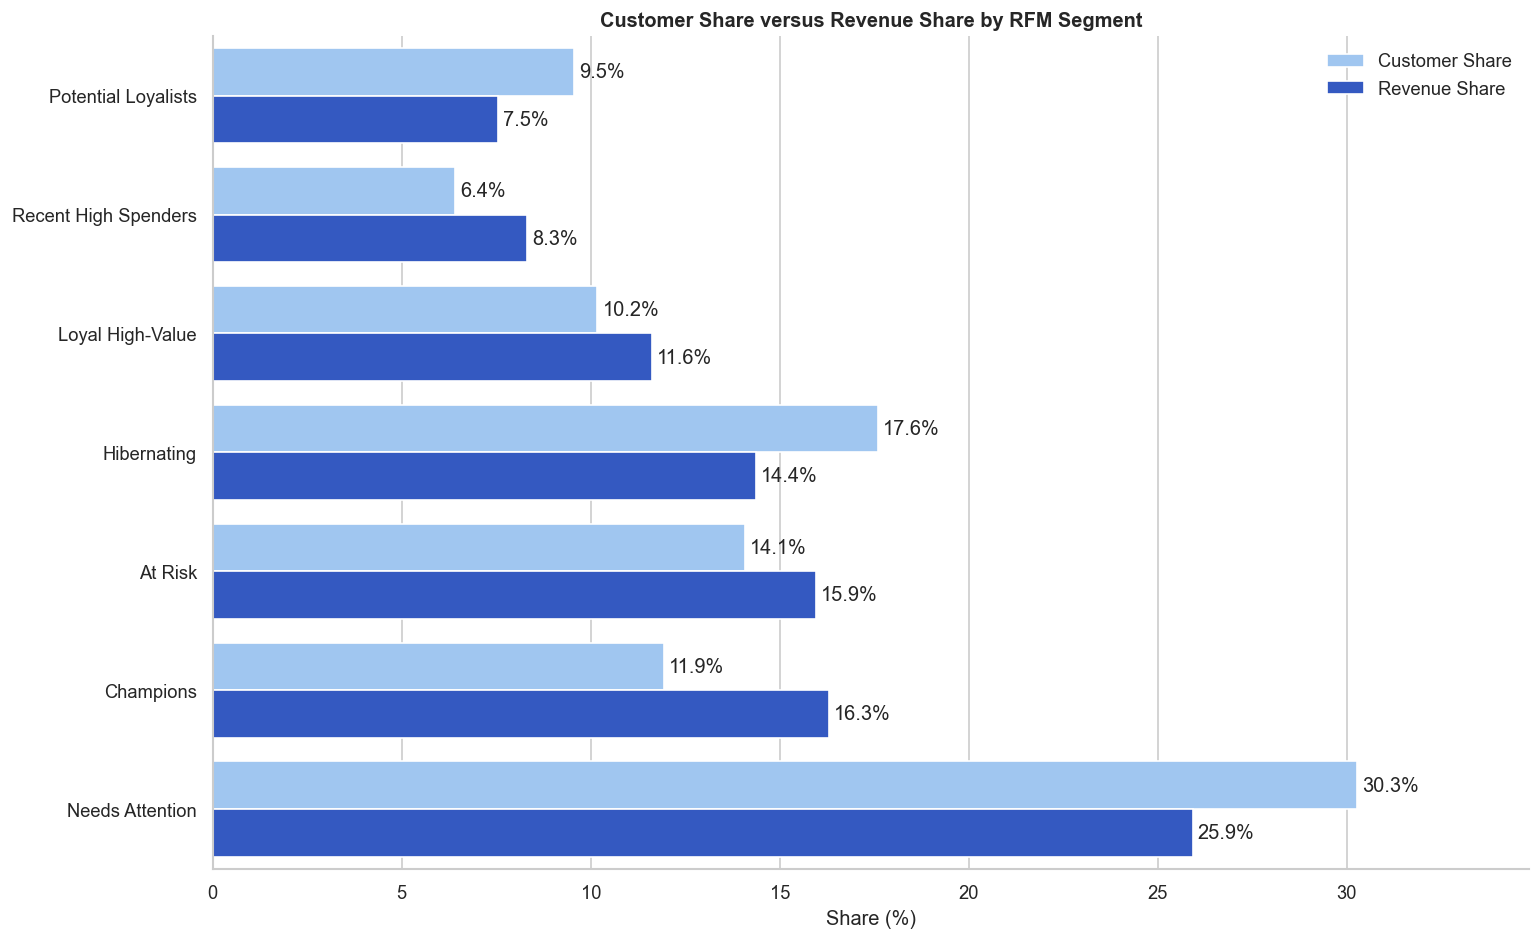

In [36]:
rfm_share_chart = (
    rfm_segment_performance[
        [
            "rfm_segment",
            "customer_share",
            "revenue_share"
        ]
    ]
    .sort_values("revenue_share", ascending=True)
    .melt(
        id_vars="rfm_segment",
        value_vars=[
            "customer_share",
            "revenue_share"
        ],
        var_name="share_type",
        value_name="share"
    )
)

rfm_share_chart["share_percent"] = (
    rfm_share_chart["share"] * 100
)

rfm_share_chart["share_type"] = (
    rfm_share_chart["share_type"]
    .replace({
        "customer_share": "Customer Share",
        "revenue_share": "Revenue Share"
    })
)


fig, axis = plt.subplots(figsize=(13, 8))

sns.barplot(
    data=rfm_share_chart,
    y="rfm_segment",
    x="share_percent",
    hue="share_type",
    palette={
        "Customer Share": "#93C5FD",
        "Revenue Share": "#1D4ED8"
    },
    ax=axis
)

axis.set_title(
    "Customer Share versus Revenue Share by RFM Segment"
)
axis.set_xlabel("Share (%)")
axis.set_ylabel("")

for container in axis.containers:
    axis.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

axis.legend(
    title="",
    frameon=False
)

axis.margins(x=0.15)

sns.despine()
plt.tight_layout()
plt.show()

### RFM Findings

- **Champions** represented **11.93% of customers** but contributed a higher **16.31% of revenue**. They purchased recently and averaged **38.1 orders**.
- **At Risk** customers represented **14.07% of customers** and contributed **15.95% of revenue**, or **$2.02 million**. Their strong historical frequency but higher average recency makes them a priority reactivation group.
- **Hibernating** customers represented **17.59% of customers**, with the highest average recency at **55.1 days**.
- **Recent High Spenders** achieved the strongest segment profit margin at **12.35%**.
- **Potential Loyalists** purchased recently but contributed only **7.53% of revenue**, indicating an opportunity to develop future value.
- **Needs Attention** was the largest segment, representing **30.28% of customers** and **25.92% of revenue**.

**Business implication:** Management should protect Champions, prioritize profitable At Risk customers for reactivation, develop Potential Loyalists through relevant cross-selling, and use lower-cost campaigns for Hibernating customers.

**Methodological note:** RFM scores are relative to customer behaviour within this dataset and use a snapshot date of **2016-01-01**.

### 8.6 Customer Lifetime Value Proxy

The dataset does not contain acquisition cost, churn probability, or confirmed customer lifespan. Therefore, I calculate a transparent 12-month profit-based CLV proxy instead of claiming a definitive lifetime value.

The estimate assumes that each customer's observed order frequency and profit margin continue for the next 12 months.

In [37]:
clv_customer = customer_performance.copy()


clv_customer["observed_tenure_days"] = (
    rfm_snapshot_date
    - clv_customer["first_order_date"]
).dt.days.clip(lower=1)

clv_customer["observed_tenure_years"] = (
    clv_customer["observed_tenure_days"]
    / 365.25
)

clv_customer["annual_order_frequency"] = (
    clv_customer["orders"]
    / clv_customer["observed_tenure_years"]
)

clv_customer["estimated_12m_profit_value"] = (
    clv_customer["average_order_value"]
    * clv_customer["annual_order_frequency"]
    * clv_customer["profit_margin"]
)


if not np.isfinite(
    clv_customer["estimated_12m_profit_value"]
).all():
    raise ValueError(
        "The CLV proxy contains infinite or invalid values."
    )


top_clv_customers = (
    clv_customer
    .nlargest(
        10,
        "estimated_12m_profit_value"
    )
    .copy()
)


top_clv_display = top_clv_customers[
    [
        "customer_name",
        "segment",
        "observed_tenure_years",
        "orders",
        "average_order_value",
        "annual_order_frequency",
        "profit_margin",
        "estimated_12m_profit_value"
    ]
].copy()

top_clv_display["observed_tenure_years"] = (
    top_clv_display["observed_tenure_years"]
    .map("{:,.2f}".format)
)

top_clv_display["average_order_value"] = (
    top_clv_display["average_order_value"]
    .map("${:,.2f}".format)
)

top_clv_display["annual_order_frequency"] = (
    top_clv_display["annual_order_frequency"]
    .map("{:,.2f}".format)
)

top_clv_display["profit_margin"] = (
    top_clv_display["profit_margin"]
    .map("{:.2%}".format)
)

top_clv_display["estimated_12m_profit_value"] = (
    top_clv_display["estimated_12m_profit_value"]
    .map("${:,.2f}".format)
)

top_clv_display = top_clv_display.rename(
    columns={
        "customer_name": "Customer",
        "segment": "Segment",
        "observed_tenure_years": "Observed Tenure Years",
        "orders": "Observed Orders",
        "average_order_value": "Average Order Value",
        "annual_order_frequency": "Annual Order Frequency",
        "profit_margin": "Profit Margin",
        "estimated_12m_profit_value": (
            "Estimated 12-Month Profit Value"
        )
    }
)

display(top_clv_display)

,Customer,Segment,Observed Tenure Years,Observed Orders,Average Order Value,Annual Order Frequency,Profit Margin,Estimated 12-Month Profit Value
732,Tamara Chand,Corporate,3.66,36,"$1,040.48",9.84,23.15%,"$2,371.09"
624,Raymond Buch,Consumer,3.58,29,"$1,020.76",8.10,28.56%,"$2,362.26"
673,Sanjit Chand,Consumer,3.88,35,$757.75,9.02,30.94%,"$2,113.55"
88,Bill Eplett,Home Office,3.72,42,$678.08,11.29,26.02%,"$1,991.54"
335,Hunter Lopez,Consumer,3.95,24,"$1,260.15",6.08,25.85%,"$1,981.26"
728,Susan Pistek,Consumer,3.32,32,$906.89,9.65,22.34%,"$1,955.76"
759,Tom Ashbrook,Home Office,3.51,29,"$1,396.14",8.26,15.59%,"$1,796.93"
6,Adrian Barton,Consumer,3.62,40,$628.08,11.03,25.54%,"$1,770.32"
323,Harry Marie,Corporate,3.98,41,$694.56,10.29,24.43%,"$1,746.74"
347,Jane Waco,Corporate,3.63,40,$757.21,11.02,20.69%,"$1,725.94"


### CLV Proxy Findings

- **Tamara Chand** achieved the highest estimated 12-month profit value at **$2,371.09**.
- **Raymond Buch** ranked closely behind at **$2,362.26**, supported by a **28.56% margin**.
- **Sanjit Chand** ranked third with an estimated value of **$2,113.55** and the highest margin among the top three customers at **30.94%**.
- The highest-ranked customers include Consumer, Corporate, and Home Office segments, indicating that high projected value is not limited to one customer segment.
- The ranking reflects the combined effect of order value, annualized purchase frequency, and profitability rather than revenue alone.

**Business implication:** The proxy can support account prioritization and retention planning, but it should not be used as a definitive lifetime-value forecast.

**Limitation:** Acquisition cost, churn probability, and actual future lifespan are unavailable. The estimate assumes that observed behaviour continues for the next 12 months.

## 9. Returns Analysis

### 9.1 Returned and Non-Returned Order Performance

I compare the original recorded revenue and profit associated with returned and non-returned orders.

The source data provides only an order-level return flag. It does not provide returned quantity, refund amount, return date, cancellation status, or return reason. Therefore, returned-order revenue is reported as associated sales and is not deducted from company revenue.

In [38]:
order_return_flag = (
    orders
    .groupby(
        "order_key",
        as_index=False
    )
    .agg(
        is_returned=("is_returned", "max")
    )
)


order_return_level = order_level.merge(
    order_return_flag,
    on="order_key",
    how="left",
    validate="one_to_one"
)

if order_return_level["is_returned"].isna().any():
    raise ValueError(
        "Some analytical orders are missing a return flag."
    )

order_return_level["return_status"] = np.where(
    order_return_level["is_returned"],
    "Returned Order",
    "Non-Returned Order"
)


return_status_performance = (
    order_return_level
    .groupby(
        "return_status",
        as_index=False
    )
    .agg(
        orders=("order_key", "nunique"),
        revenue=("revenue", "sum"),
        profit=("profit", "sum"),
        quantity=("quantity", "sum")
    )
)

return_status_performance["order_share"] = (
    return_status_performance["orders"]
    / total_orders
)

return_status_performance["profit_margin"] = (
    return_status_performance["profit"]
    / return_status_performance["revenue"]
)

return_status_performance["average_order_value"] = (
    return_status_performance["revenue"]
    / return_status_performance["orders"]
)


return_status_display = return_status_performance.copy()

return_status_display["revenue"] = (
    return_status_display["revenue"].map("${:,.2f}".format)
)

return_status_display["profit"] = (
    return_status_display["profit"].map("${:,.2f}".format)
)

return_status_display["order_share"] = (
    return_status_display["order_share"].map("{:.2%}".format)
)

return_status_display["profit_margin"] = (
    return_status_display["profit_margin"].map("{:.2%}".format)
)

return_status_display["average_order_value"] = (
    return_status_display["average_order_value"]
    .map("${:,.2f}".format)
)

return_status_display = return_status_display.rename(
    columns={
        "return_status": "Return Status",
        "orders": "Orders",
        "revenue": "Associated Revenue",
        "profit": "Associated Profit",
        "quantity": "Associated Quantity",
        "order_share": "Order Share",
        "profit_margin": "Profit Margin",
        "average_order_value": "Average Order Value"
    }
)

display(return_status_display)

,Return Status,Orders,Associated Revenue,Associated Profit,Associated Quantity,Order Share,Profit Margin,Average Order Value
0,Non-Returned Order,24660,"$12,116,689.92","$1,406,078.51",170648,95.81%,11.60%,$491.35
1,Returned Order,1079,"$525,817.33","$61,378.16",7664,4.19%,11.67%,$487.32


### 9.2 Products Associated with Returned Orders

Because returns are recorded only at the order level, I identify products that appeared in returned orders. I do not claim that every product line in a returned order was physically returned.

In [39]:
product_return_counts = (
    orders.loc[orders["is_returned"]]
    .groupby(
        [
            "product_id",
            "product_name",
            "category",
            "sub_category"
        ],
        as_index=False
    )
    .agg(
        returned_order_associations=("order_key", "nunique")
    )
)


product_return_analysis = product_performance.merge(
    product_return_counts,
    on=[
        "product_id",
        "product_name",
        "category",
        "sub_category"
    ],
    how="left",
    validate="one_to_one"
)

product_return_analysis["returned_order_associations"] = (
    product_return_analysis["returned_order_associations"]
    .fillna(0)
    .astype(int)
)

product_return_analysis["returned_order_association_rate"] = (
    product_return_analysis["returned_order_associations"]
    / product_return_analysis["orders_containing_product"]
)


top_products_by_return_count = (
    product_return_analysis
    .nlargest(
        10,
        "returned_order_associations"
    )
    .copy()
)


minimum_product_orders = 20

high_return_rate_products = (
    product_return_analysis
    .loc[
        product_return_analysis["orders_containing_product"]
        .ge(minimum_product_orders)
    ]
    .nlargest(
        10,
        "returned_order_association_rate"
    )
    .copy()
)


def format_product_return_table(dataframe):
    formatted_table = dataframe[
        [
            "product_name",
            "category",
            "sub_category",
            "orders_containing_product",
            "returned_order_associations",
            "returned_order_association_rate"
        ]
    ].copy()

    formatted_table["returned_order_association_rate"] = (
        formatted_table["returned_order_association_rate"]
        .map("{:.2%}".format)
    )

    return formatted_table.rename(
        columns={
            "product_name": "Product",
            "category": "Category",
            "sub_category": "Sub-Category",
            "orders_containing_product": "Orders",
            "returned_order_associations": (
                "Returned-Order Associations"
            ),
            "returned_order_association_rate": (
                "Returned-Order Association Rate"
            )
        }
    )


print("Top 10 Products by Returned-Order Association Count")
display(
    format_product_return_table(
        top_products_by_return_count
    )
)

print(
    "Top 10 Association Rates among Products with at Least",
    minimum_product_orders,
    "Orders"
)

display(
    format_product_return_table(
        high_return_rate_products
    )
)

Top 10 Products by Returned-Order Association Count


,Product,Category,Sub-Category,Orders,Returned-Order Associations,Returned-Order Association Rate
1907,Staples,Office Supplies,Fasteners,222,12,5.41%
2693,"Smead File Cart, Single Width",Office Supplies,Storage,77,9,11.69%
1120,"Binney & Smith Sketch Pad, Blue",Office Supplies,Art,52,6,11.54%
2691,"Smead File Cart, Blue",Office Supplies,Storage,42,6,14.29%
2730,"Tenex Folders, Single Width",Office Supplies,Storage,36,6,16.67%
285,"Novimex Executive Leather Armchair, Adjustable",Furniture,Chairs,39,5,12.82%
1103,"Binney & Smith Highlighters, Easy-Erase",Office Supplies,Art,32,5,15.62%
1115,"Binney & Smith Pencil Sharpener, Water Color",Office Supplies,Art,55,5,9.09%
1158,"Boston Pens, Fluorescent",Office Supplies,Art,43,5,11.63%
1442,"Cardinal Binder, Recycled",Office Supplies,Binders,43,5,11.63%


Top 10 Association Rates among Products with at Least 20 Orders


,Product,Category,Sub-Category,Orders,Returned-Order Associations,Returned-Order Association Rate
3676,"Nokia Signal Booster, Full Size",Technology,Phones,20,4,20.00%
291,"Novimex Rocking Chair, Black",Furniture,Chairs,22,4,18.18%
1376,"Avery 3-Hole Punch, Economy",Office Supplies,Binders,22,4,18.18%
2730,"Tenex Folders, Single Width",Office Supplies,Storage,36,6,16.67%
601,"Rubbermaid Frame, Duo Pack",Furniture,Furnishings,25,4,16.00%
1103,"Binney & Smith Highlighters, Easy-Erase",Office Supplies,Art,32,5,15.62%
57,"Dania Library with Doors, Pine",Furniture,Bookcases,20,3,15.00%
1660,"Ames Business Envelopes, Security-Tint",Office Supplies,Envelopes,20,3,15.00%
1704,"Cameo Manila Envelope, Set of 50",Office Supplies,Envelopes,20,3,15.00%
2034,"Harbour Creations Removable Labels, 5000 Label...",Office Supplies,Labels,20,3,15.00%


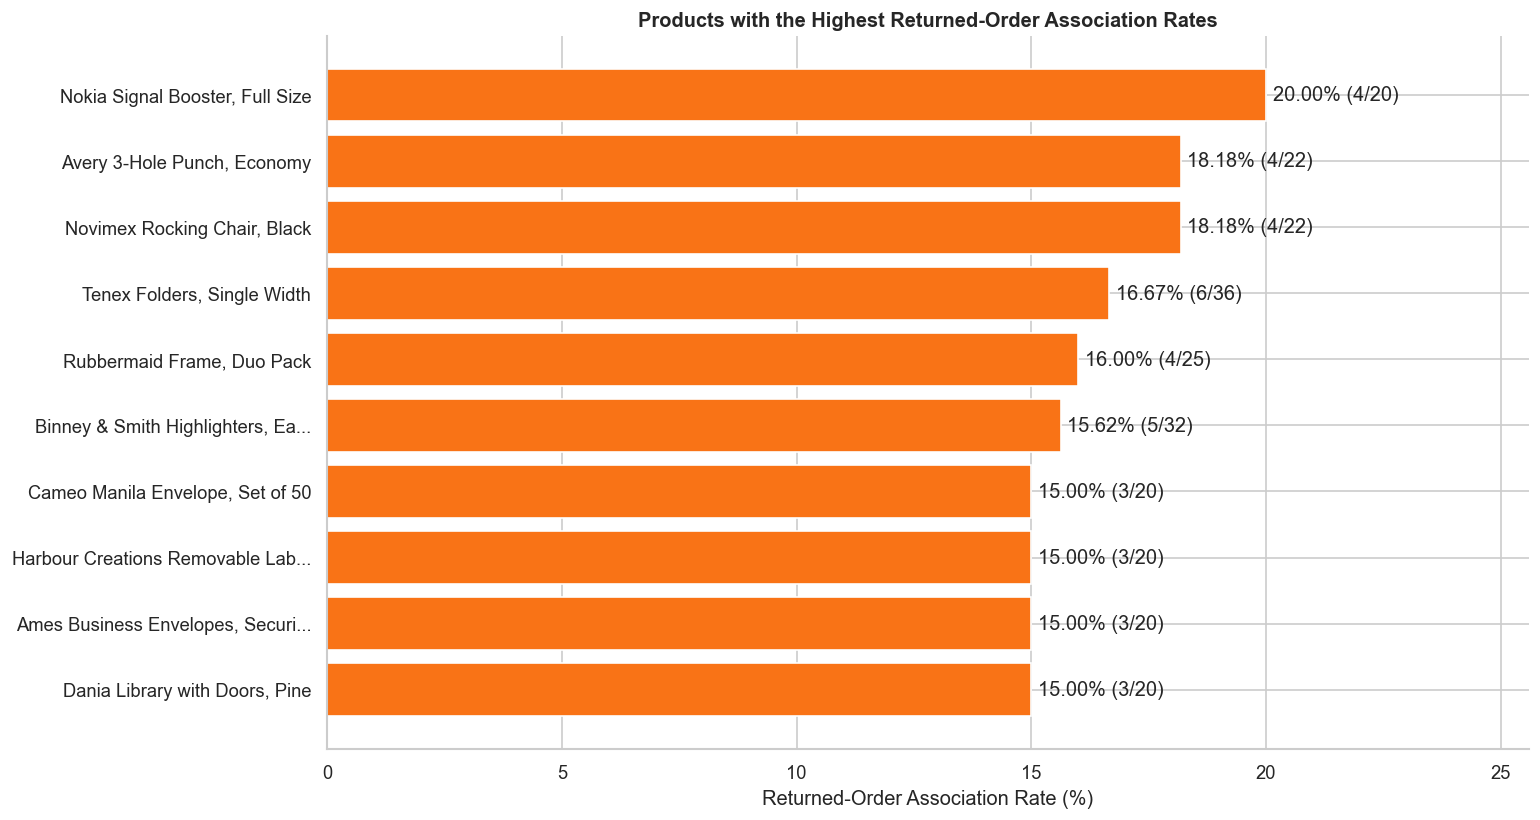

In [40]:
product_return_chart = (
    high_return_rate_products
    .sort_values(
        "returned_order_association_rate",
        ascending=True
    )
    .copy()
)

product_return_chart["product_label"] = (
    product_return_chart["product_name"]
    .map(shorten_product_name)
)


fig, axis = plt.subplots(figsize=(13, 7))

return_rate_bars = axis.barh(
    product_return_chart["product_label"],
    (
        product_return_chart[
            "returned_order_association_rate"
        ]
        * 100
    ),
    color="#F97316"
)

axis.set_title(
    "Products with the Highest Returned-Order Association Rates"
)
axis.set_xlabel(
    "Returned-Order Association Rate (%)"
)
axis.set_ylabel("")

axis.bar_label(
    return_rate_bars,
    labels=[
        (
            f"{rate:.2%} "
            f"({returned_orders}/{all_orders})"
        )
        for rate, returned_orders, all_orders in zip(
            product_return_chart[
                "returned_order_association_rate"
            ],
            product_return_chart[
                "returned_order_associations"
            ],
            product_return_chart[
                "orders_containing_product"
            ]
        )
    ],
    padding=4
)

axis.margins(x=0.28)

sns.despine()
plt.tight_layout()
plt.show()

### Returns Findings and Limitations

- **1,079 orders**, or **4.19% of analytical orders**, were identified as returned.
- Returned orders were associated with **$525.82 thousand in recorded revenue** and **$61.38 thousand in recorded profit**.
- Returned and non-returned orders had similar recorded average order values and profit margins.
- **Staples** appeared in the highest number of returned orders, with 12 associations, but its **5.41% rate** was influenced by its large order volume.
- **Nokia Signal Booster, Full Size** recorded the highest association rate among products with at least 20 orders, at **20.00%**.
- **Tenex Folders, Single Width** appeared in both priority rankings, with six returned-order associations and a **16.67% association rate**.
- **Smead File Cart, Single Width** recorded nine returned-order associations and an **11.69% association rate**.

**Business implication:** Management should prioritize products with both meaningful return counts and elevated association rates for quality, description, packaging, and fulfilment review.

**Limitation:** Returns are available only at the order level. The dataset does not identify the exact returned product, returned quantity, refund amount, return date, reason, or cancellation status. Therefore, these results measure association with returned orders rather than confirmed product-level return rates.

## 10. Analysis Validation

I validate the major analytical tables against the executive KPI baseline before documenting final EDA findings.

In [41]:
eda_validation_checks = pd.DataFrame({
    "Validation Check": [
        "Monthly revenue reconciles",
        "Monthly profit reconciles",
        "All 48 months remain available",
        "Category revenue reconciles",
        "Category profit reconciles",
        "Sub-category revenue reconciles",
        "Sub-category profit reconciles",
        "Product revenue reconciles",
        "Product profit reconciles",
        "Market revenue reconciles",
        "Market profit reconciles",
        "Country revenue reconciles",
        "Country profit reconciles",
        "Region revenue reconciles",
        "Region profit reconciles",
        "Customer revenue reconciles",
        "Customer profit reconciles",
        "New and returning revenue reconciles",
        "Order-level revenue reconciles",
        "Order-level order count reconciles",
        "Returned-order count reconciles",
        "RFM customer count reconciles",
        "RFM customer keys remain unique",
        "No missing RFM segment labels"
    ],
    "Passed": [
        np.isclose(
            monthly_performance["revenue"].sum(),
            total_revenue
        ),
        np.isclose(
            monthly_performance["profit"].sum(),
            total_profit
        ),
        len(monthly_performance) == 48,
        np.isclose(
            category_performance["revenue"].sum(),
            total_revenue
        ),
        np.isclose(
            category_performance["profit"].sum(),
            total_profit
        ),
        np.isclose(
            sub_category_performance["revenue"].sum(),
            total_revenue
        ),
        np.isclose(
            sub_category_performance["profit"].sum(),
            total_profit
        ),
        np.isclose(
            product_performance["revenue"].sum(),
            total_revenue
        ),
        np.isclose(
            product_performance["profit"].sum(),
            total_profit
        ),
        np.isclose(
            market_performance["revenue"].sum(),
            total_revenue
        ),
        np.isclose(
            market_performance["profit"].sum(),
            total_profit
        ),
        np.isclose(
            country_performance["revenue"].sum(),
            total_revenue
        ),
        np.isclose(
            country_performance["profit"].sum(),
            total_profit
        ),
        np.isclose(
            region_performance["revenue"].sum(),
            total_revenue
        ),
        np.isclose(
            region_performance["profit"].sum(),
            total_profit
        ),
        np.isclose(
            customer_performance["revenue"].sum(),
            total_revenue
        ),
        np.isclose(
            customer_performance["profit"].sum(),
            total_profit
        ),
        np.isclose(
            new_returning_performance["revenue"].sum(),
            total_revenue
        ),
        np.isclose(
            order_level["revenue"].sum(),
            total_revenue
        ),
        len(order_level) == total_orders,
        (
            order_return_level.loc[
                order_return_level["is_returned"],
                "order_key"
            ].nunique()
            == returned_orders
        ),
        len(rfm) == unique_customers,
        rfm["customer_key"].is_unique,
        rfm["rfm_segment"].notna().all()
    ]
})

display(eda_validation_checks)

print(
    "All EDA validations passed:",
    eda_validation_checks["Passed"].all()
)

,Validation Check,Passed
0,Monthly revenue reconciles,True
1,Monthly profit reconciles,True
2,All 48 months remain available,True
3,Category revenue reconciles,True
4,Category profit reconciles,True
5,Sub-category revenue reconciles,True
6,Sub-category profit reconciles,True
7,Product revenue reconciles,True
8,Product profit reconciles,True
9,Market revenue reconciles,True


All EDA validations passed: True


## 11. Executive EDA Summary

### Key Findings

1. Revenue increased from **$2.26 million in 2012** to **$4.30 million in 2015**, while profit increased from **$248.94 thousand** to **$504.17 thousand**.
2. Growth was driven mainly by higher order volume. Average order value declined from **$500.32** in 2012 to **$485.31** in 2015.
3. November and December were the strongest seasonal revenue periods, but December's **10.73% margin** was lower than October's **13.41% peak margin**.
4. Technology generated the highest revenue and profit. Furniture contributed **32.51% of revenue** but only **19.43% of profit**.
5. Tables was the only loss-making sub-category, producing a **$64.08 thousand loss** and reducing Furniture margin by approximately **3.47 percentage points**.
6. **677 loss-making products** generated **19.28% of company revenue** but produced a combined **$247.84 thousand loss**.
7. Discounts above **20%** were loss-making in aggregate. The above-30% discount band produced a **$793.53 thousand loss** and a **92.44% loss-line rate**.
8. Asia Pacific generated the highest market revenue, while Europe generated the highest market profit and strongest margin.
9. **31 countries** were loss-making, led by Turkey and Nigeria. High-loss countries also recorded high average discounts.
10. Returning-customer orders generated **96.86% of revenue**. The At Risk RFM segment represented **$2.02 million in historical revenue**.
11. The returned-order rate was **4.19%**. Product-level findings represent association with returned orders because exact returned items and refund values are unavailable.

### Preliminary Management Priorities

- Review discount approvals above 20%, with immediate focus on discounts above 30%.
- Investigate Tables and high-revenue loss-making products at product, country, and transaction levels.
- Protect Champions and high-profit customers while prioritizing profitable At Risk customers for reactivation.
- Improve margin in Asia Pacific, LATAM, and high-revenue low-margin regions.
- Review products with both elevated returned-order association counts and rates.

These priorities are preliminary and will be strengthened through statistical testing and advanced analysis in the next phase.